# PDAC internal val — pretrained pan-cancer Hist2Pheno

CODEX PDAC has **56 fold-0** coverslip regions. This notebook only draws the
**top 5** by matched-cell **L2 macro AUROC** (these five are also #1–#5 among
all 182 fold-0 sections). Individual-dataset notebook:
`code/CODEX_pdac/Data_process_visual_codex_HEcelltype_pdac.ipynb`.

Checkpoint: `data/PanCancer/result_all_spatial/cross_dataset_cv/D_emph_L2_spatial_pancancer/best_mlp_gpu.pt`  
This is **not** the single-dataset model. Fold 0 was held out of that weight file.

```bash
bash code/Internal_val/demo.sh status
ONLY=PDAC bash code/Internal_val/demo.sh predict
```


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code" / "Internal_val"))

import internal_val as iv

DATASET = "PDAC"
SAVE_FIGURES = False
SAVE_PAPER = True
fold = iv.fold0_table(DATASET)
viz = iv.top_fold0_samples(DATASET, 5)
rank = iv.rank_fold0(DATASET)
cols = [
    "rank_ds", "n_ds", "rank_all", "n_all",
    "sample", "n_matched",
    "macro_auc_L1_cells", "macro_auc_L12_cells", "macro_auc_L2_cells",
]
rank_show = rank[cols].copy()
print(f"{DATASET} fold 0: {len(fold)} sections; drawing top {len(viz)} by L2 AUROC")
print("top5", viz)
display(Markdown("### Top 5 PDAC fold-0 by L2 AUROC"))
display(rank_show.head(5))
display(Markdown("### All 56 (rank table; notebook does not draw the rest)"))
display(rank_show)


PDAC fold 0: 56 sections; drawing top 5 by L2 AUROC
top5 ['Charvill-94_c003_v001_r001_reg126', 'Charvill-94_c001_v001_r001_reg039', 'Charvill-94_c001_v001_r001_reg059', 'Charvill-94_c001_v001_r001_reg087', 'Charvill-94_c003_v001_r001_reg111']

 rank_ds  n_ds  rank_all  n_all                            sample  n_matched  macro_auc_L1_cells  macro_auc_L12_cells  macro_auc_L2_cells
       1    56         1    182 Charvill-94_c003_v001_r001_reg126       6593            0.837156             0.842255            0.822733
       2    56         2    182 Charvill-94_c001_v001_r001_reg039       2811            0.883268             0.871629            0.811563
       3    56         3    182 Charvill-94_c001_v001_r001_reg059       4267            0.858551             0.835332            0.800969
       4    56         4    182 Charvill-94_c001_v001_r001_reg087       8845            0.831180             0.857928            0.800698
       5    56         5    182 Charvill-94_c003_v001_r001_reg111 

rank_ds,n_ds,rank_all,n_all,sample,n_matched,macro_auc_L1_cells,macro_auc_L12_cells,macro_auc_L2_cells
1,56,1,182,Charvill-94_c003_v001_r001_reg126,6593,0.8372,0.8423,0.8227
2,56,2,182,Charvill-94_c001_v001_r001_reg039,2811,0.8833,0.8716,0.8116
3,56,3,182,Charvill-94_c001_v001_r001_reg059,4267,0.8586,0.8353,0.8010
4,56,4,182,Charvill-94_c001_v001_r001_reg087,8845,0.8312,0.8579,0.8007
5,56,5,182,Charvill-94_c003_v001_r001_reg111,4565,0.8664,0.8412,0.7987


## Top 5 — 4×3 panels (GT / Hist2Pheno / ROC / StarDist-all)

### Charvill-94_c003_v001_r001_reg126  L2 AUROC=0.823  #1/56 PDAC fold 0  (#1/182 all fold 0)

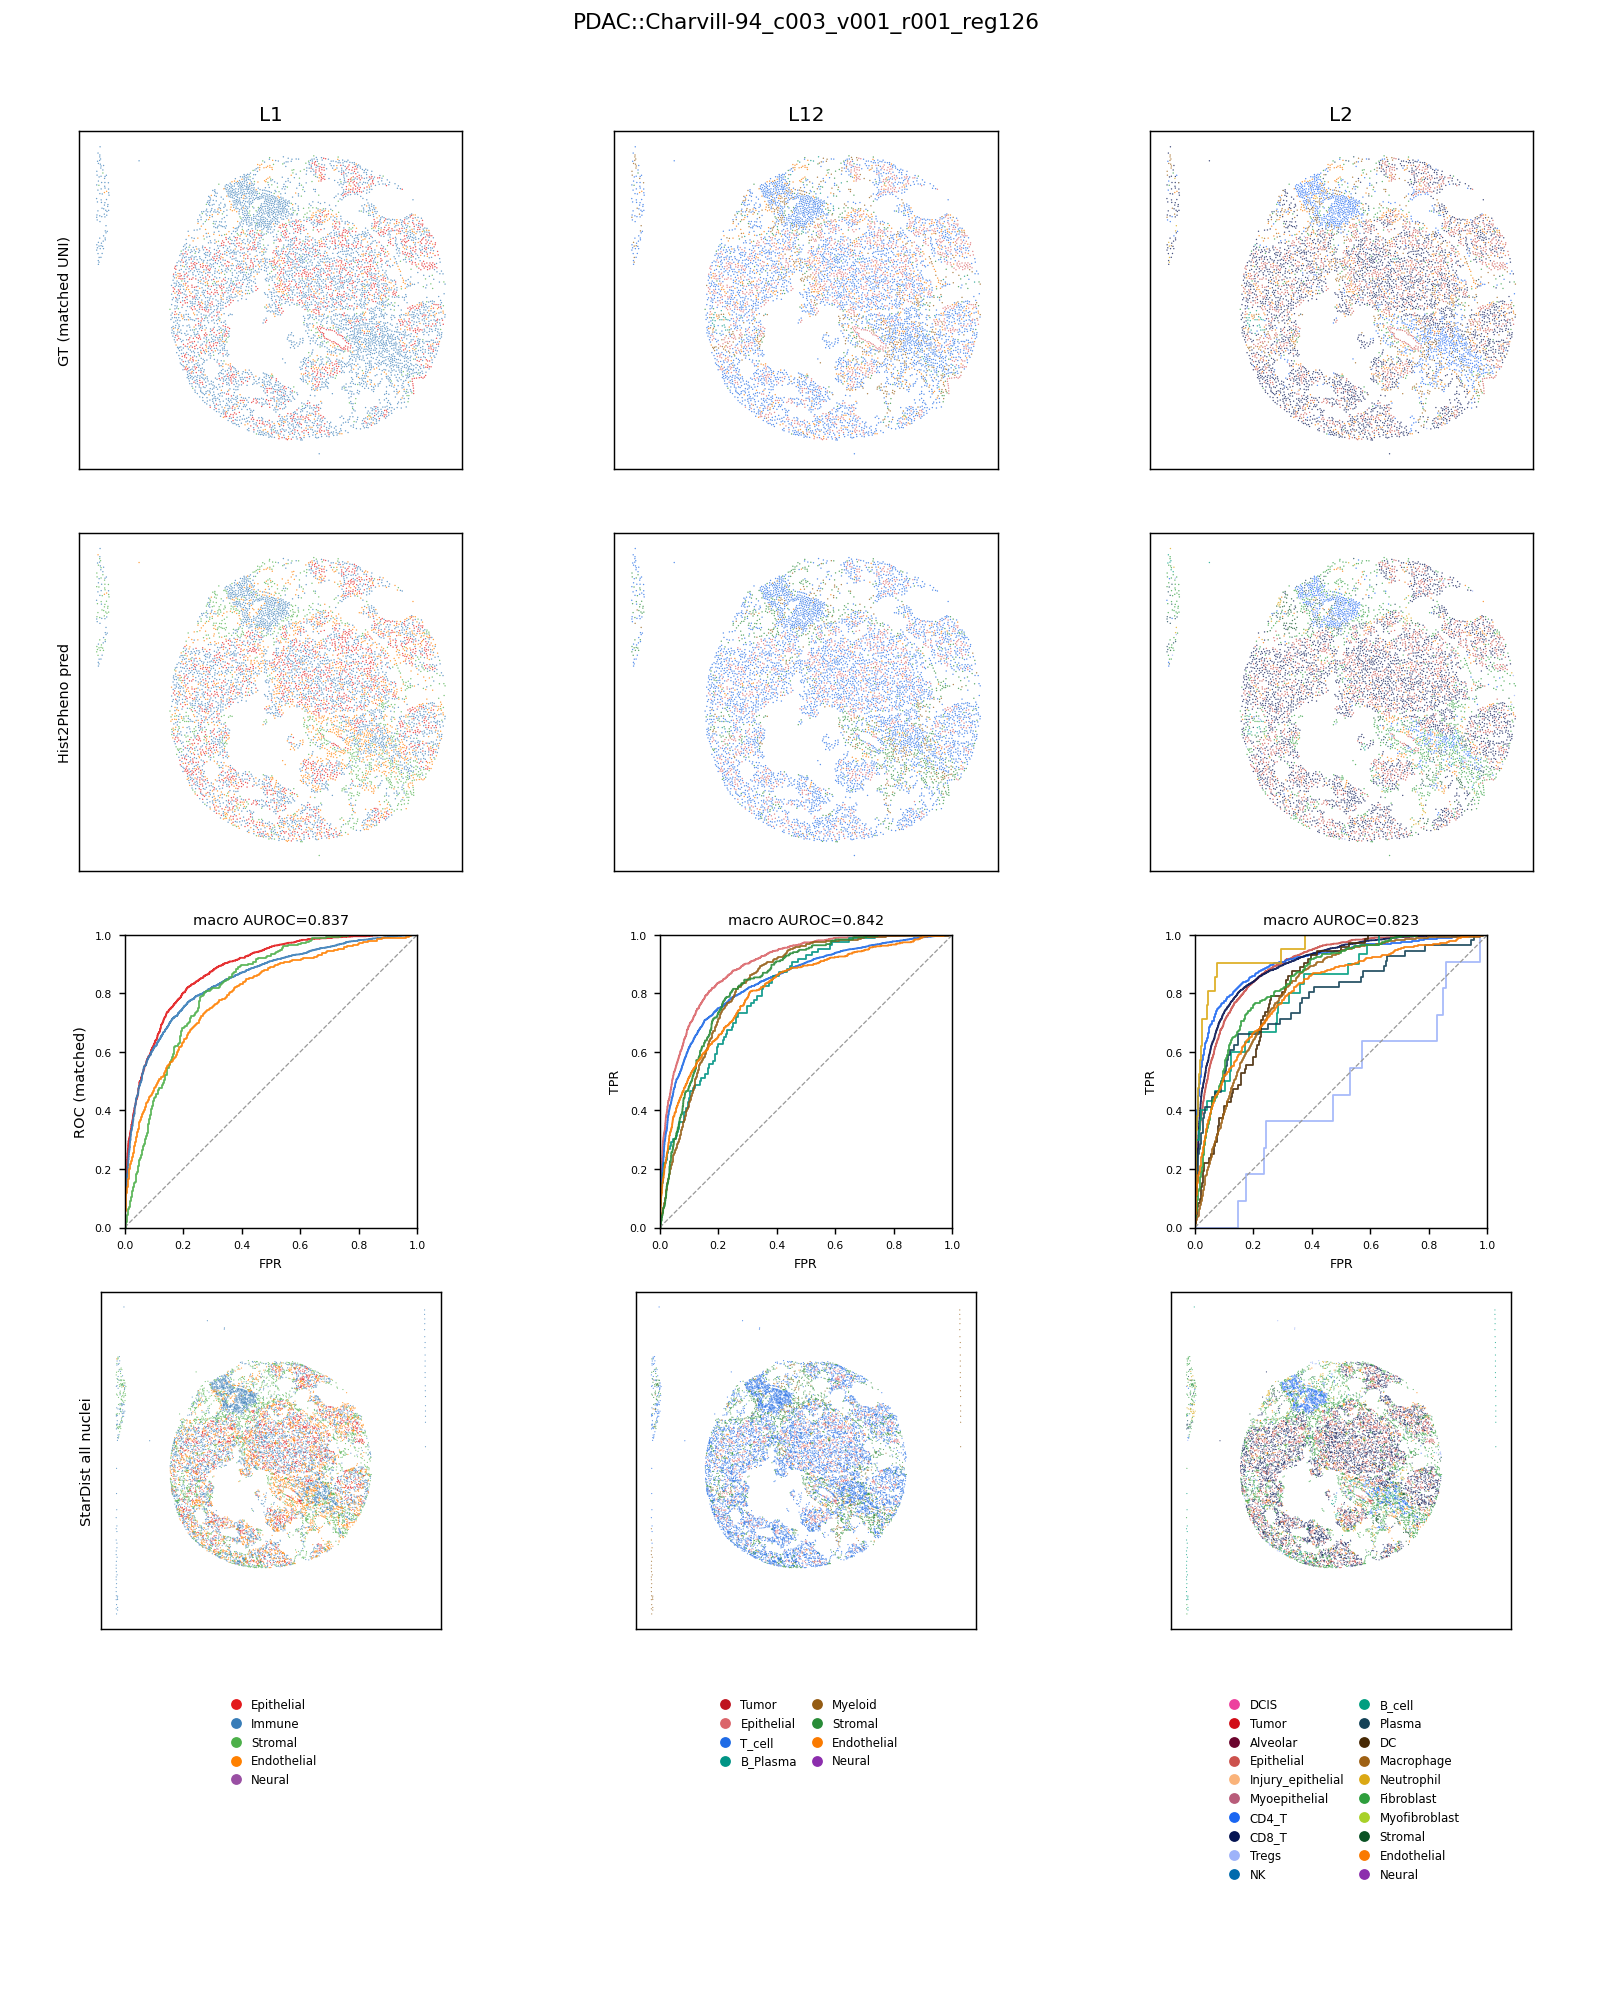

### Charvill-94_c001_v001_r001_reg039  L2 AUROC=0.812  #2/56 PDAC fold 0  (#2/182 all fold 0)

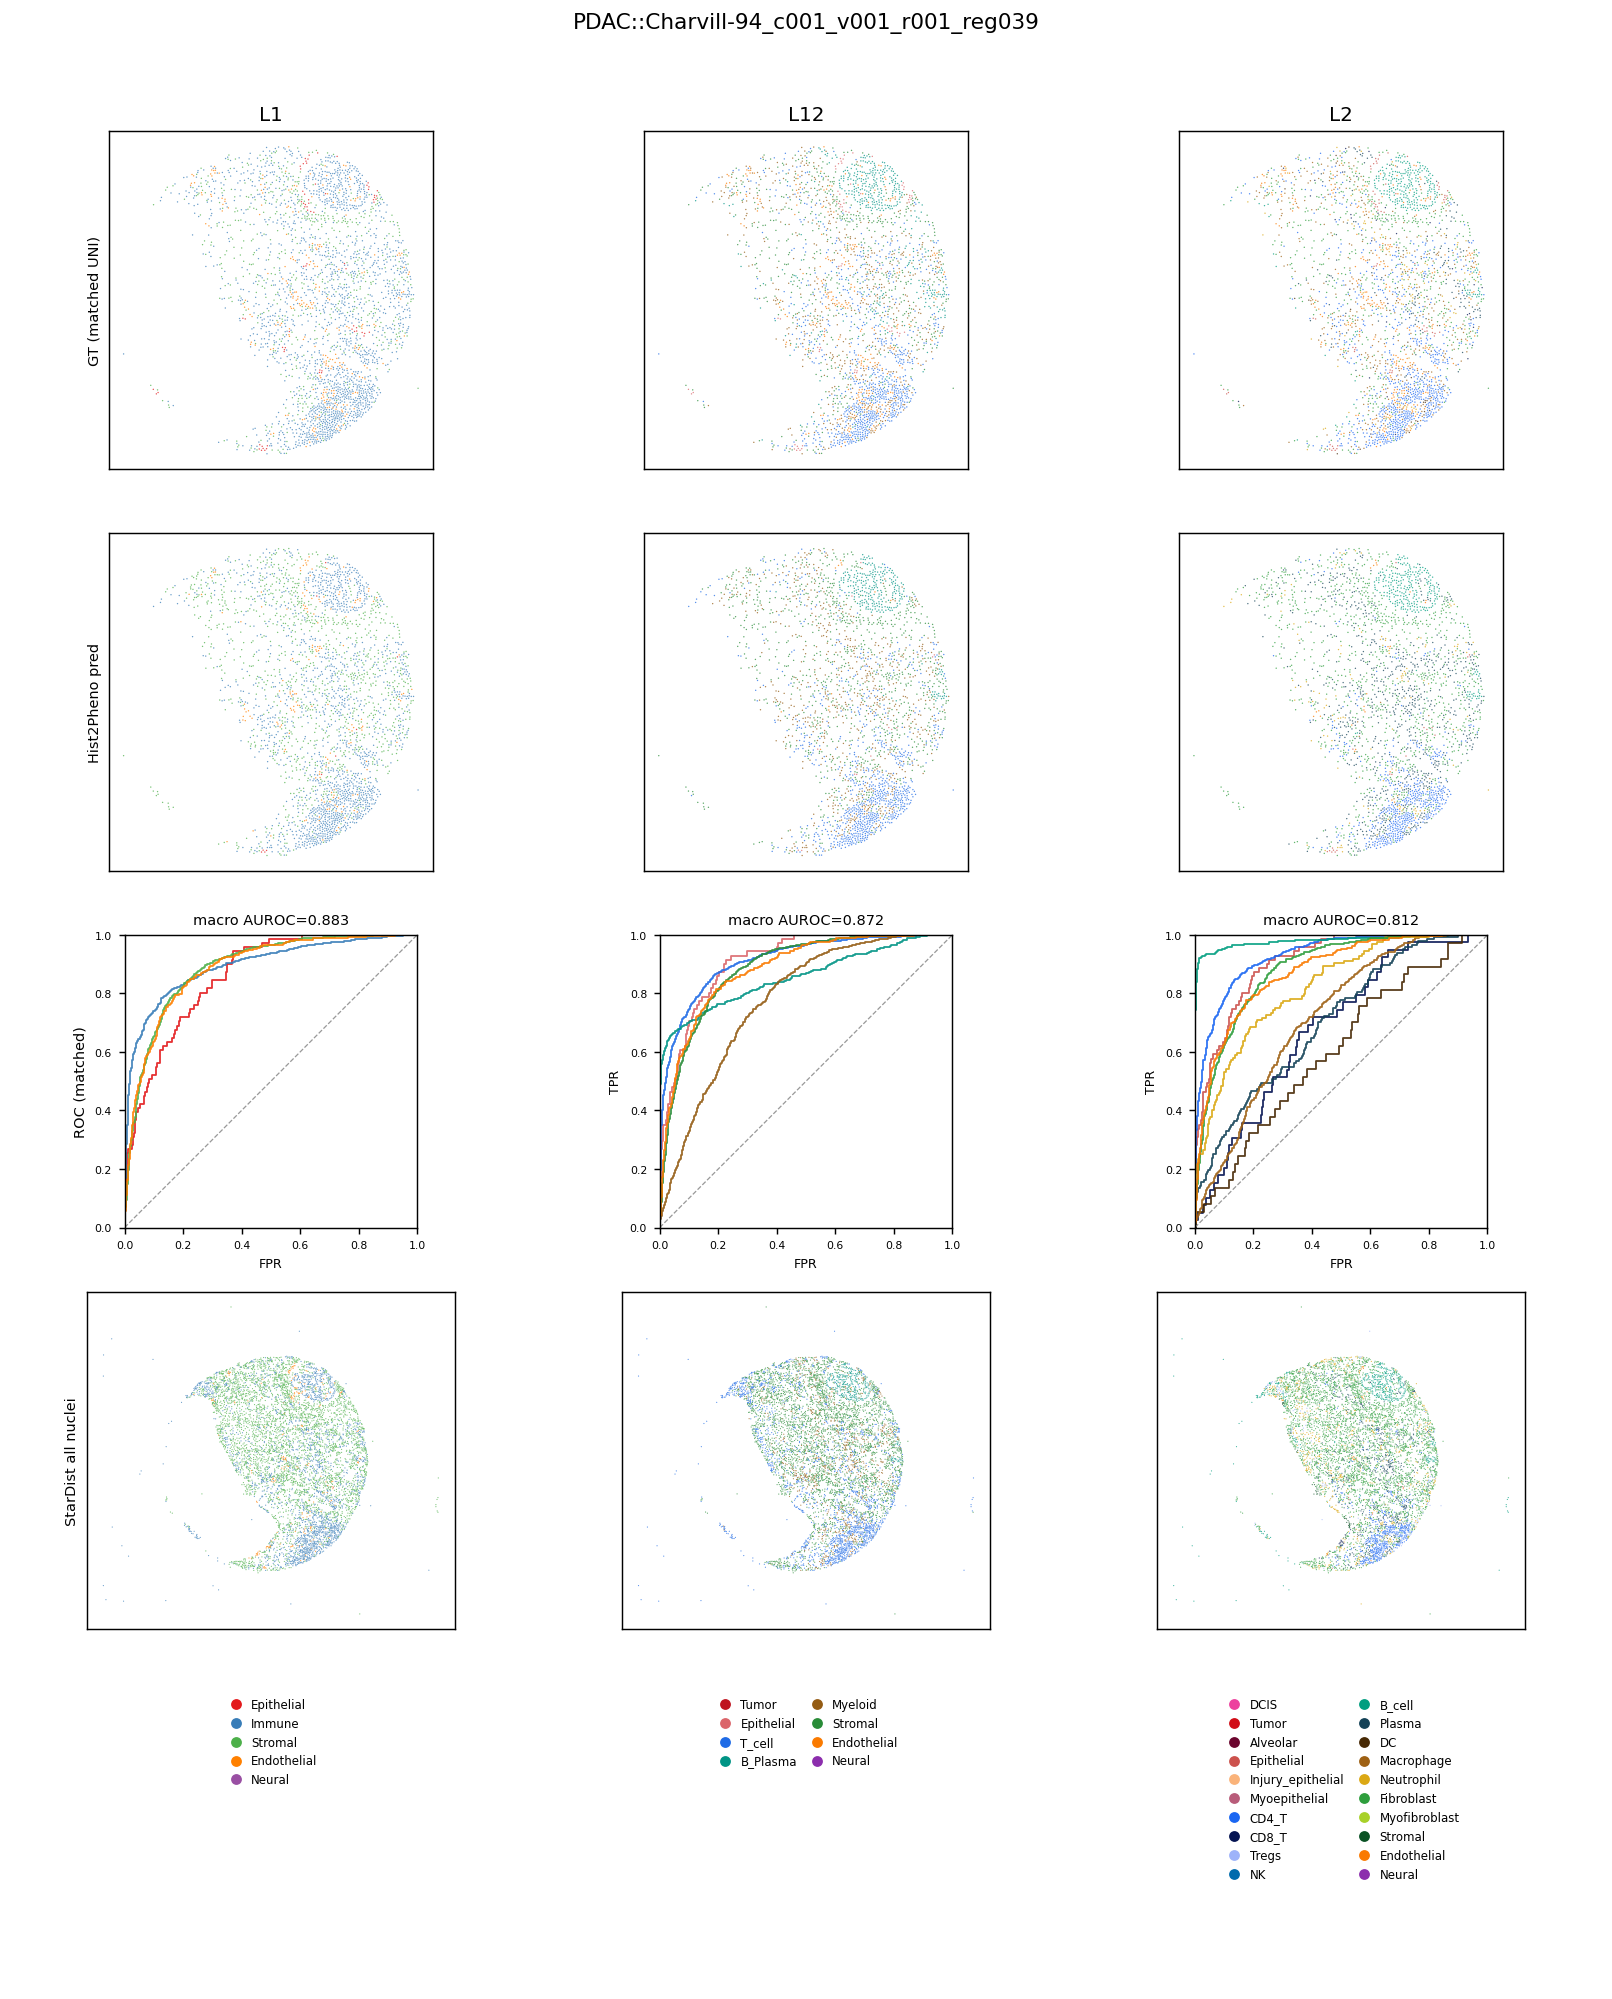

### Charvill-94_c001_v001_r001_reg059  L2 AUROC=0.801  #3/56 PDAC fold 0  (#3/182 all fold 0)

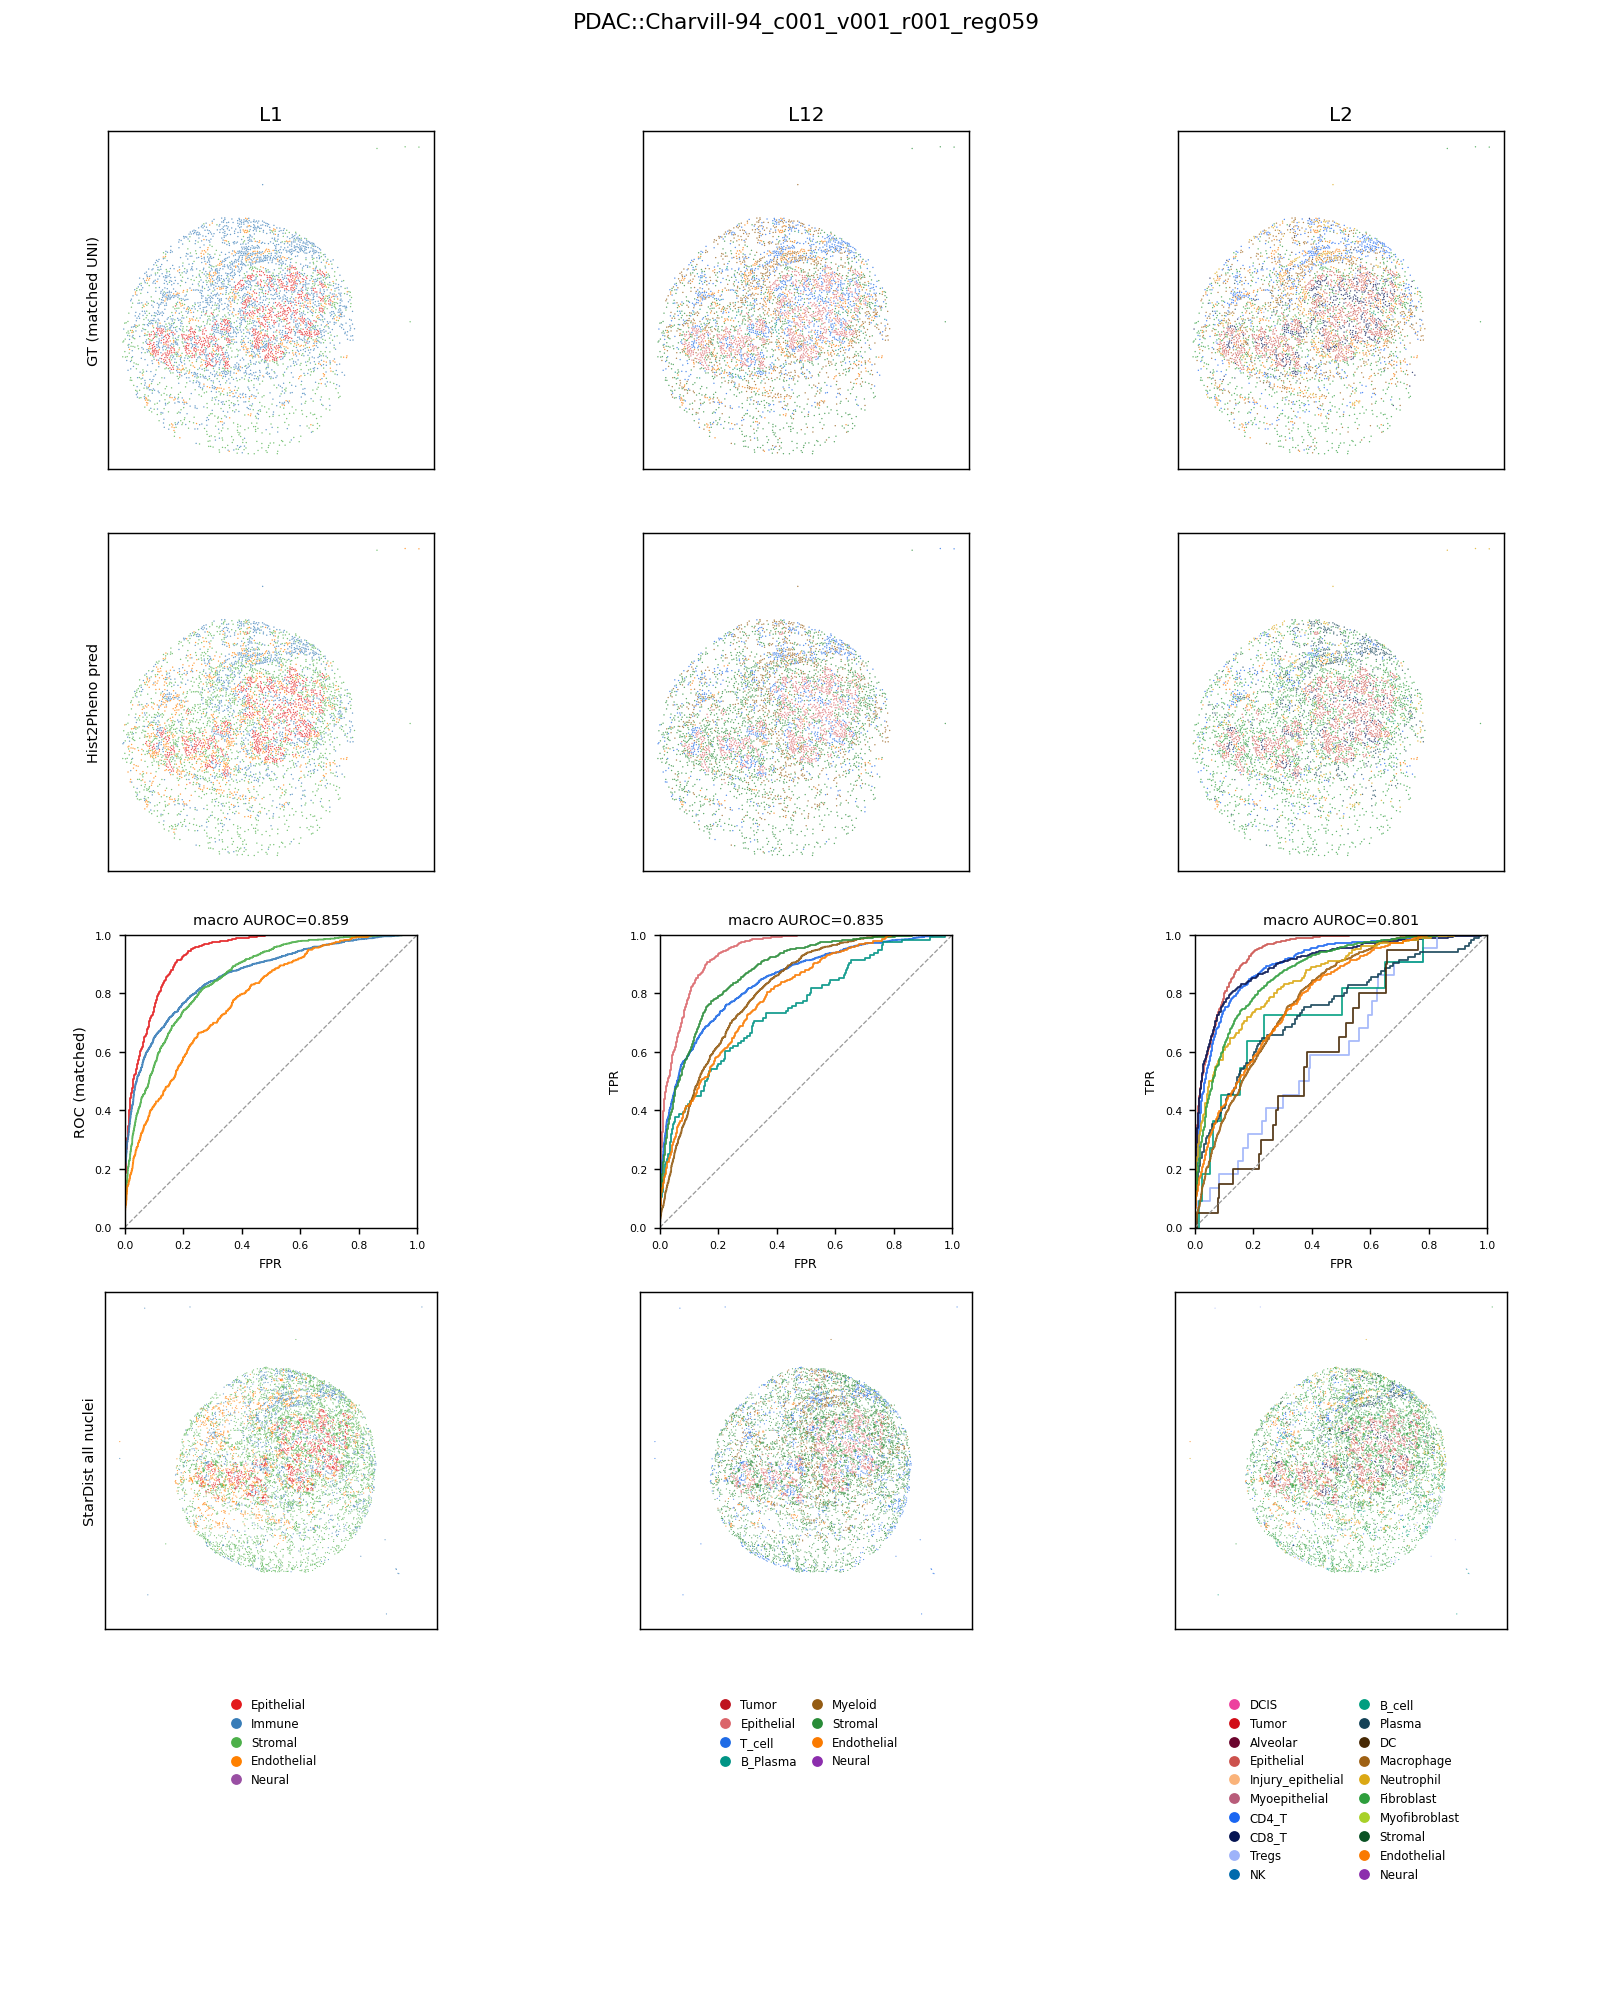

### Charvill-94_c001_v001_r001_reg087  L2 AUROC=0.801  #4/56 PDAC fold 0  (#4/182 all fold 0)

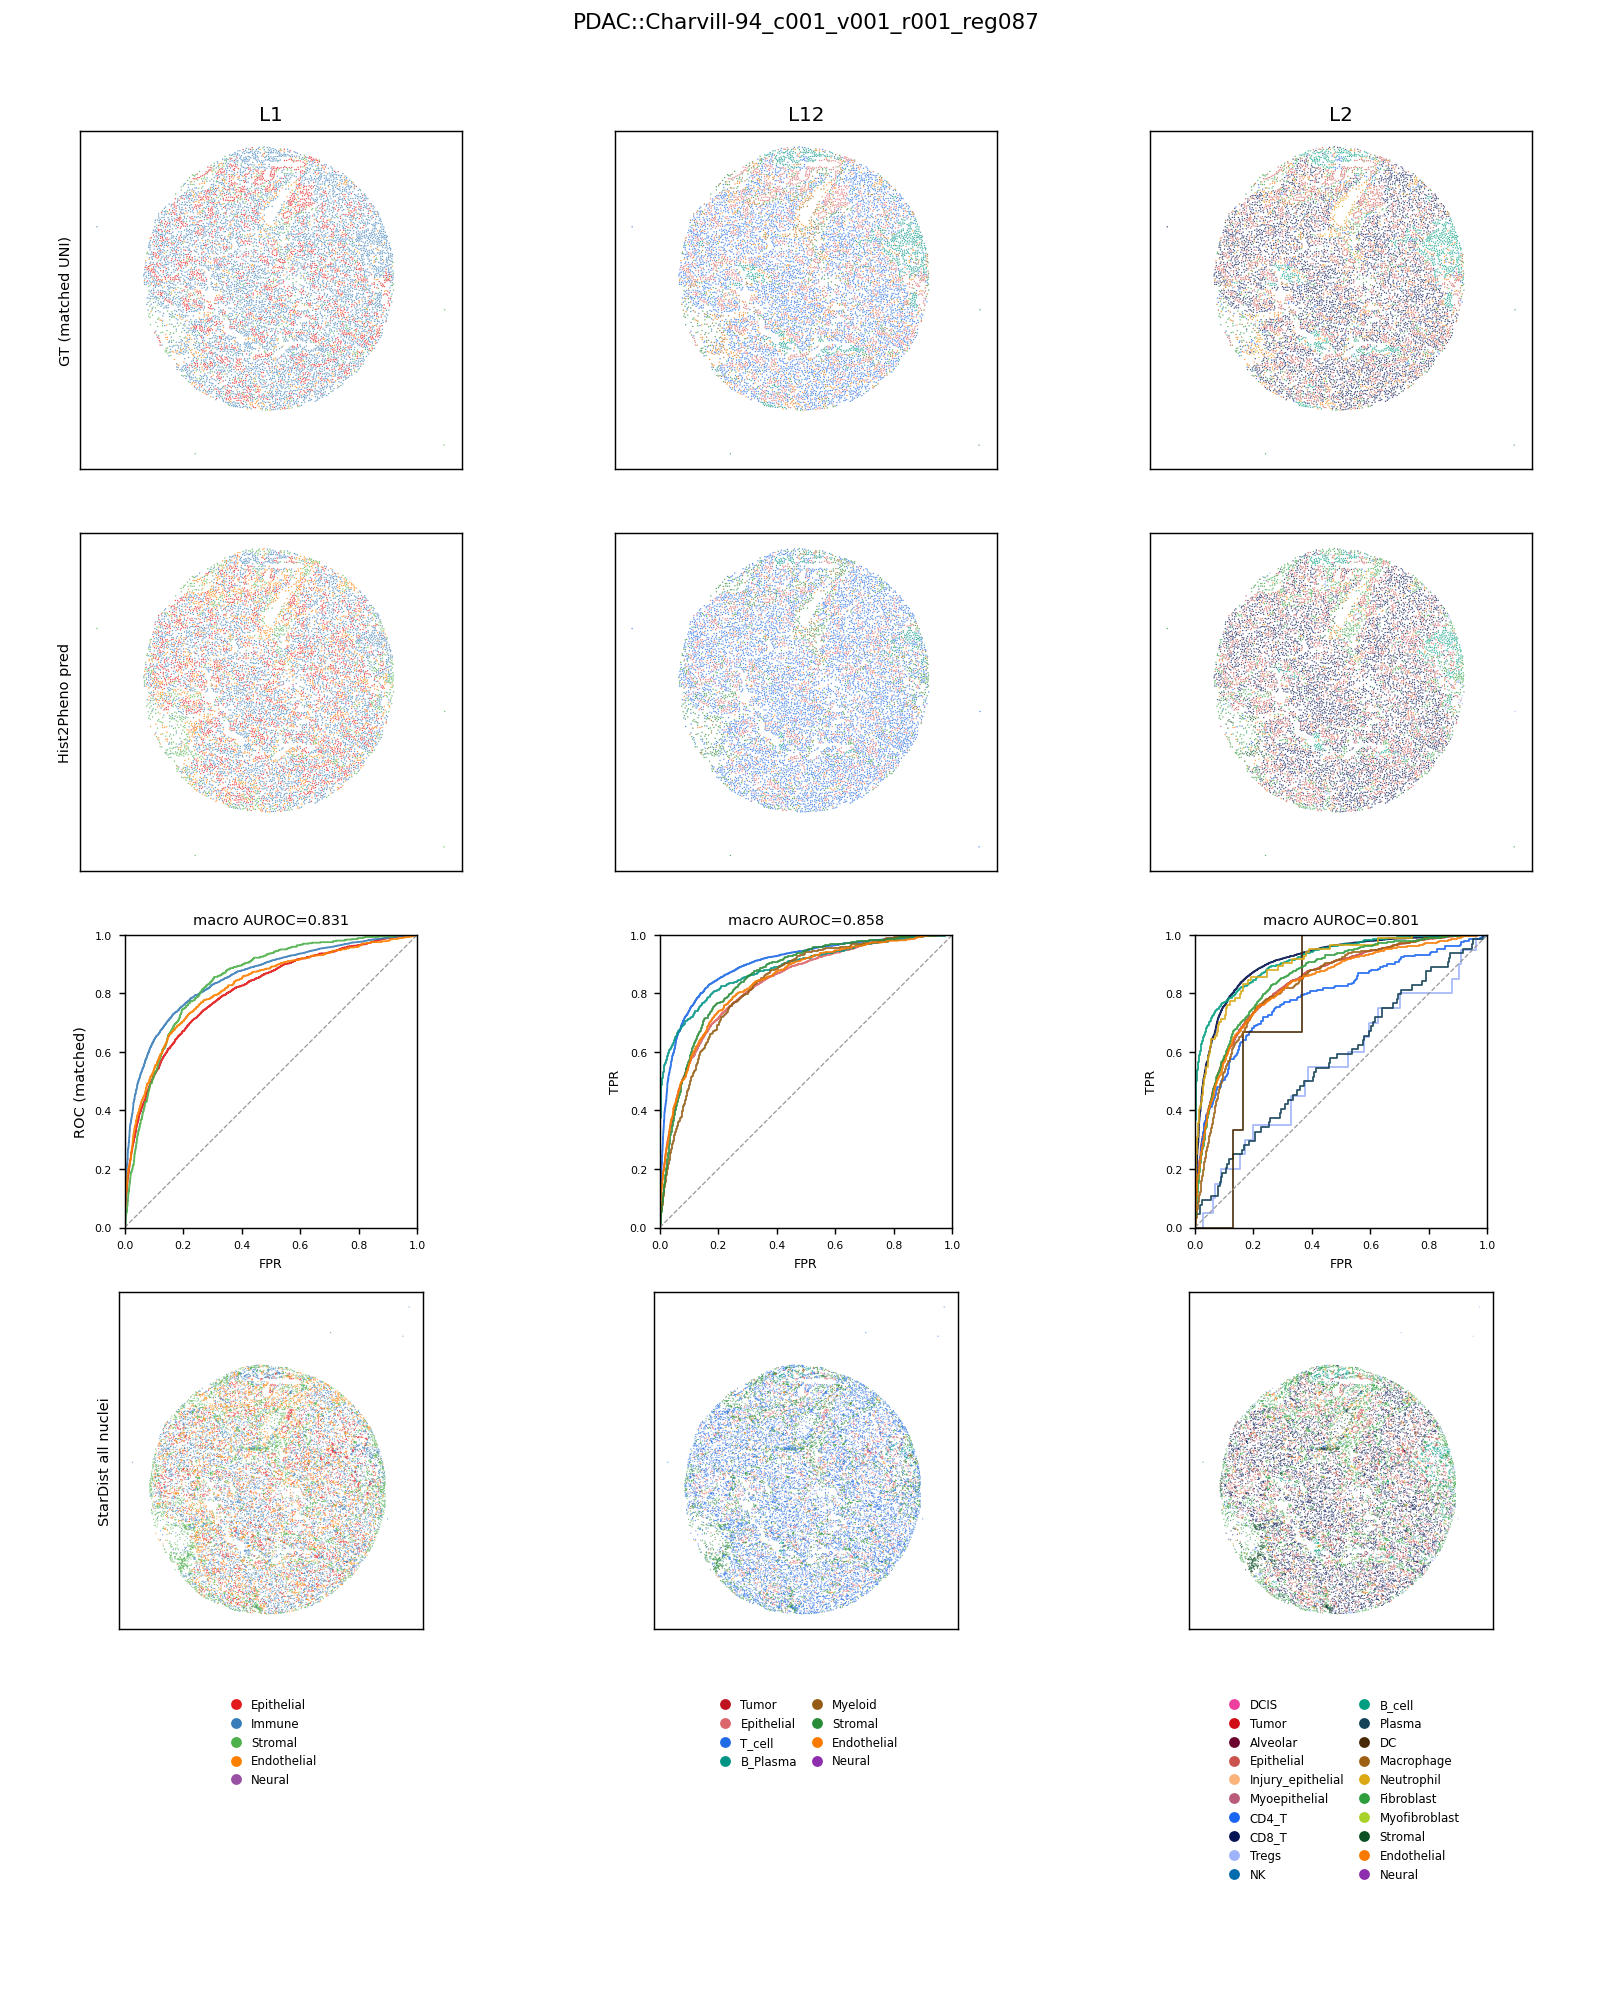

### Charvill-94_c003_v001_r001_reg111  L2 AUROC=0.799  #5/56 PDAC fold 0  (#5/182 all fold 0)

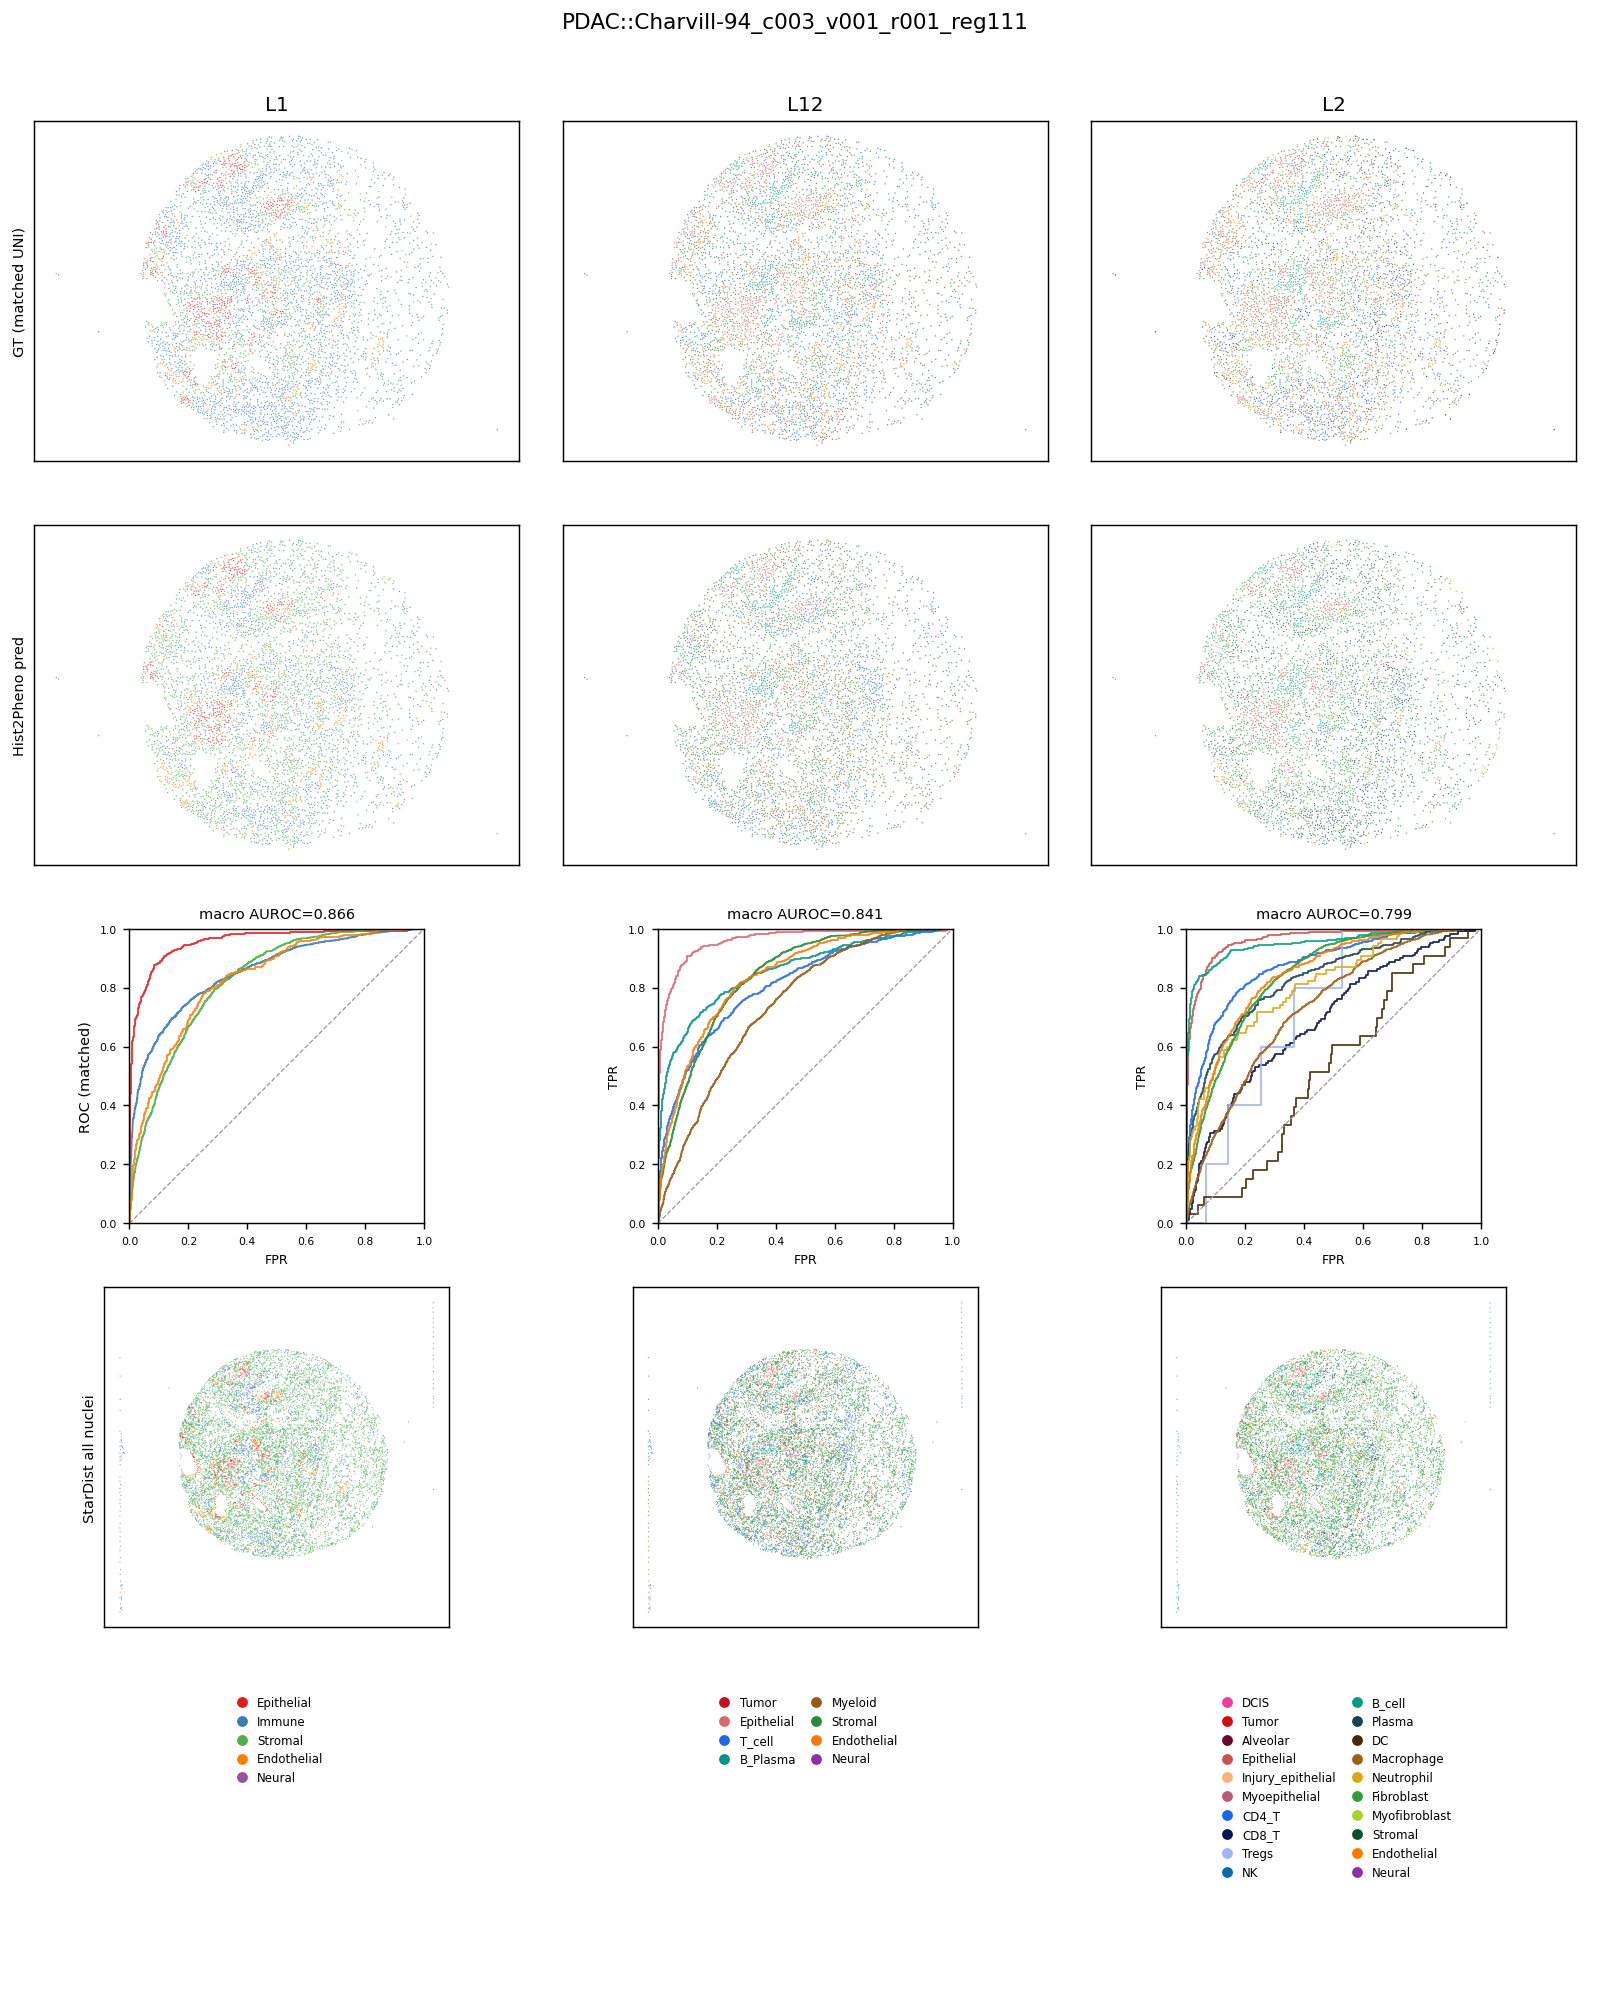

In [2]:
display(Markdown("## Top 5 — 4×3 panels (GT / Hist2Pheno / ROC / StarDist-all)"))
missing = []
for sample in viz:
    panel = iv.pred_paths(DATASET, sample)["panel"]
    display(Markdown(f"### {iv.rank_label(DATASET, sample)}"))
    if panel.is_file():
        display(Image(filename=str(panel)))
    else:
        missing.append(sample)
        print("missing panel", sample)
if missing:
    print("Run: ONLY=%s bash code/Internal_val/demo.sh predict" % DATASET)


## Top 5 — GT vs pretrained L2 (matched nuclei)

### Charvill-94_c003_v001_r001_reg126  L2 AUROC=0.823  #1/56 PDAC fold 0  (#1/182 all fold 0)

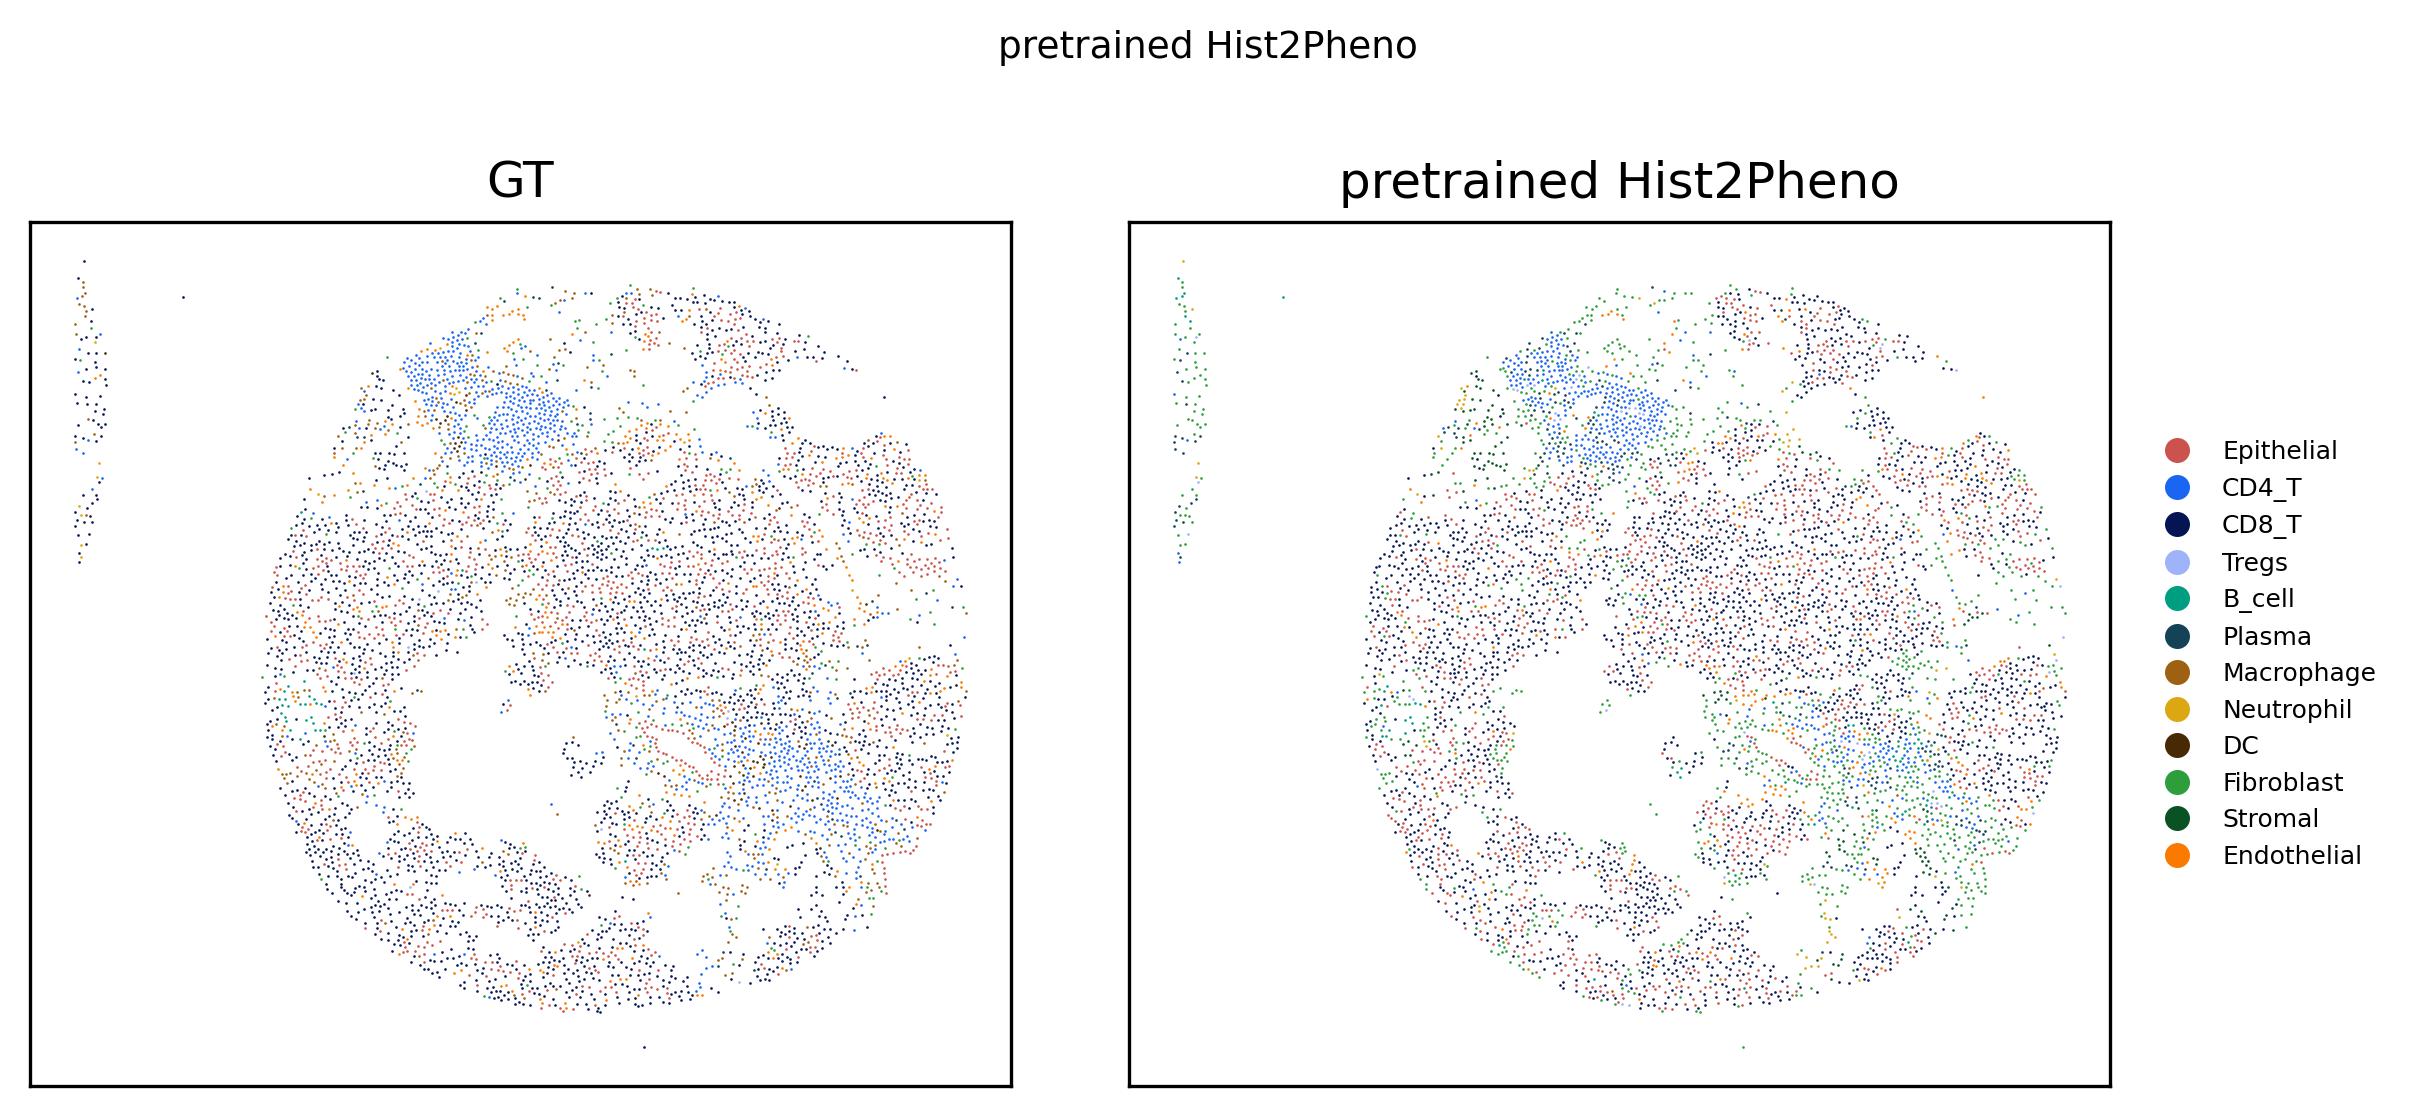

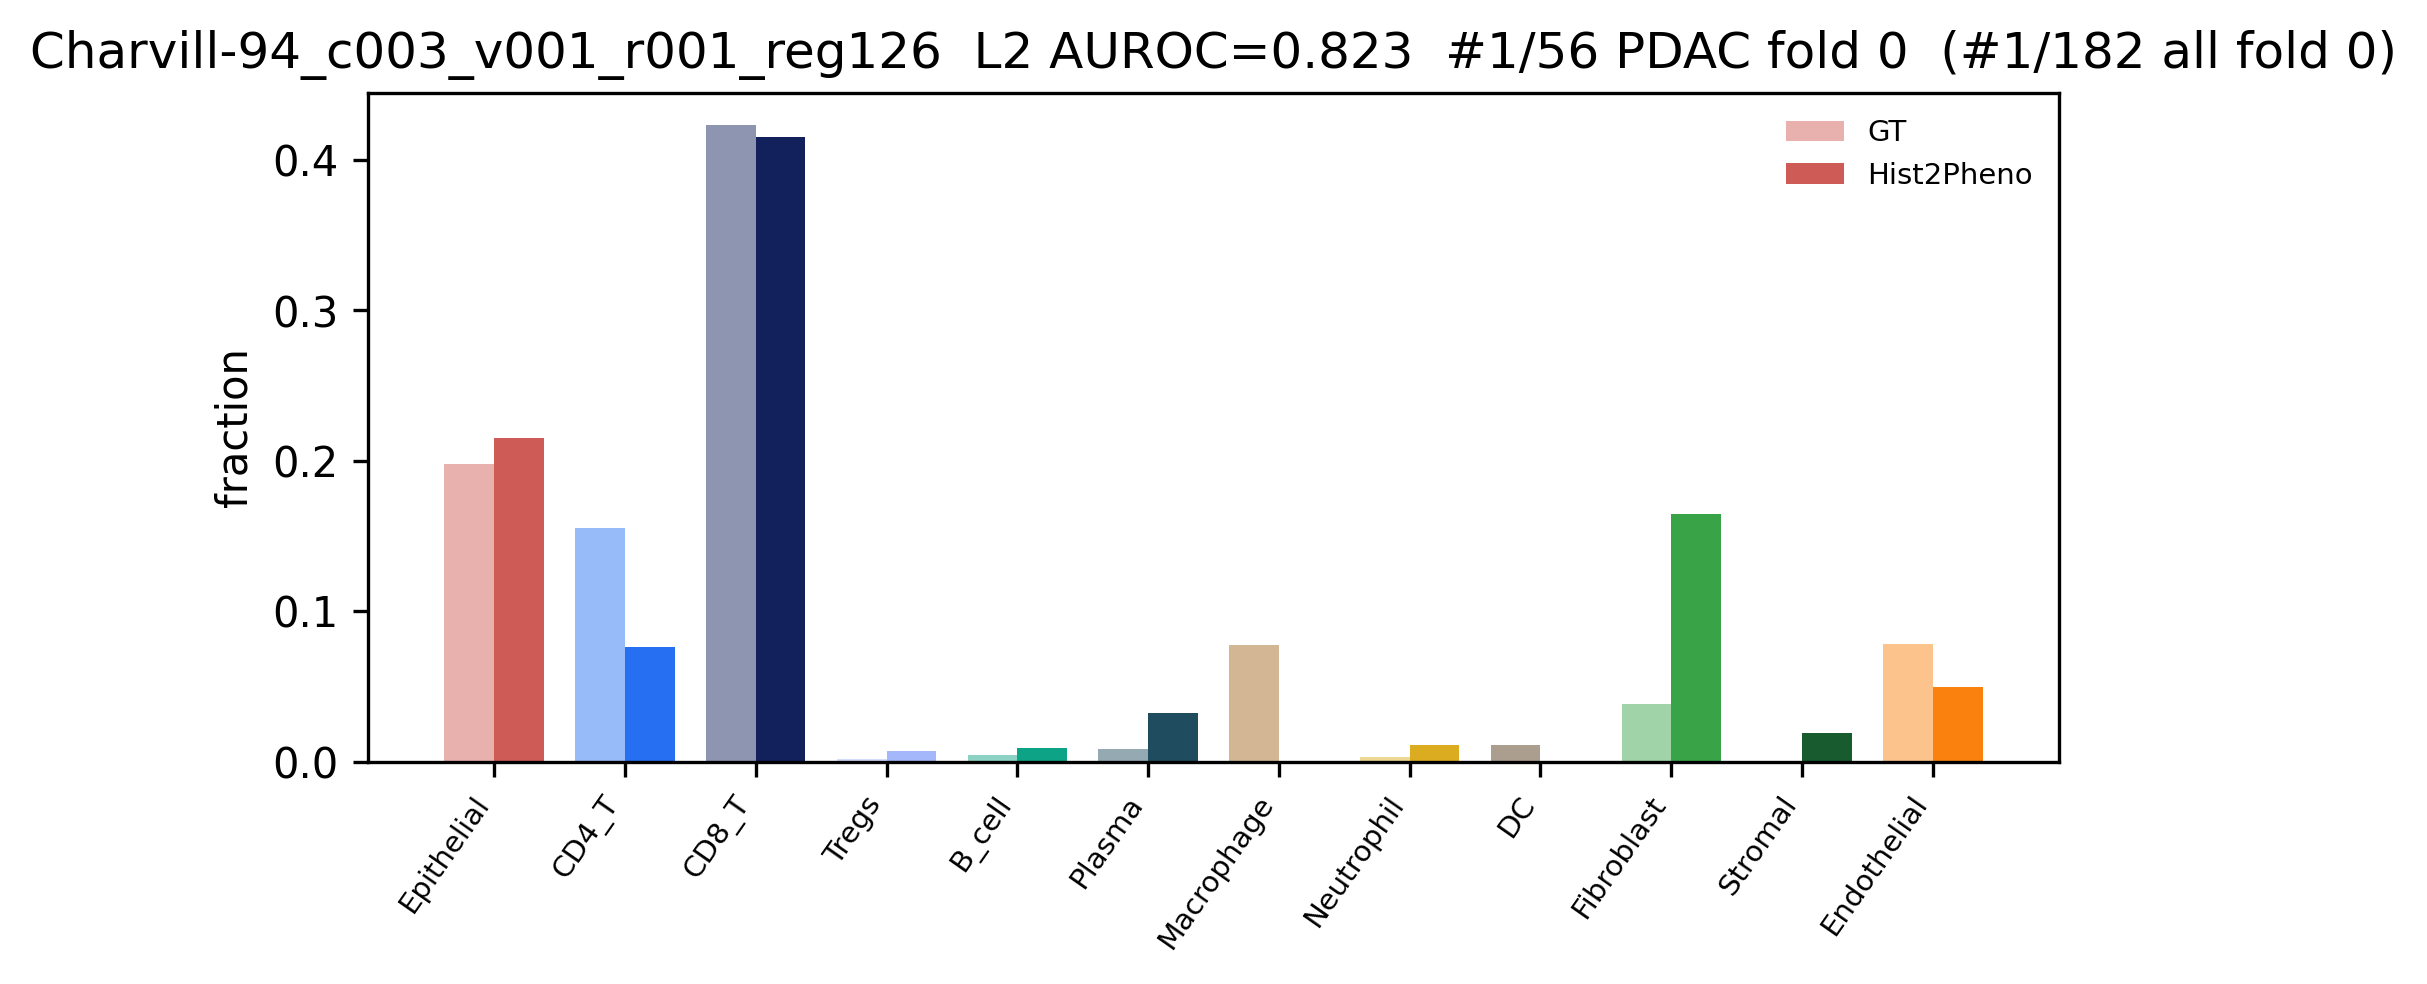

### Charvill-94_c001_v001_r001_reg039  L2 AUROC=0.812  #2/56 PDAC fold 0  (#2/182 all fold 0)

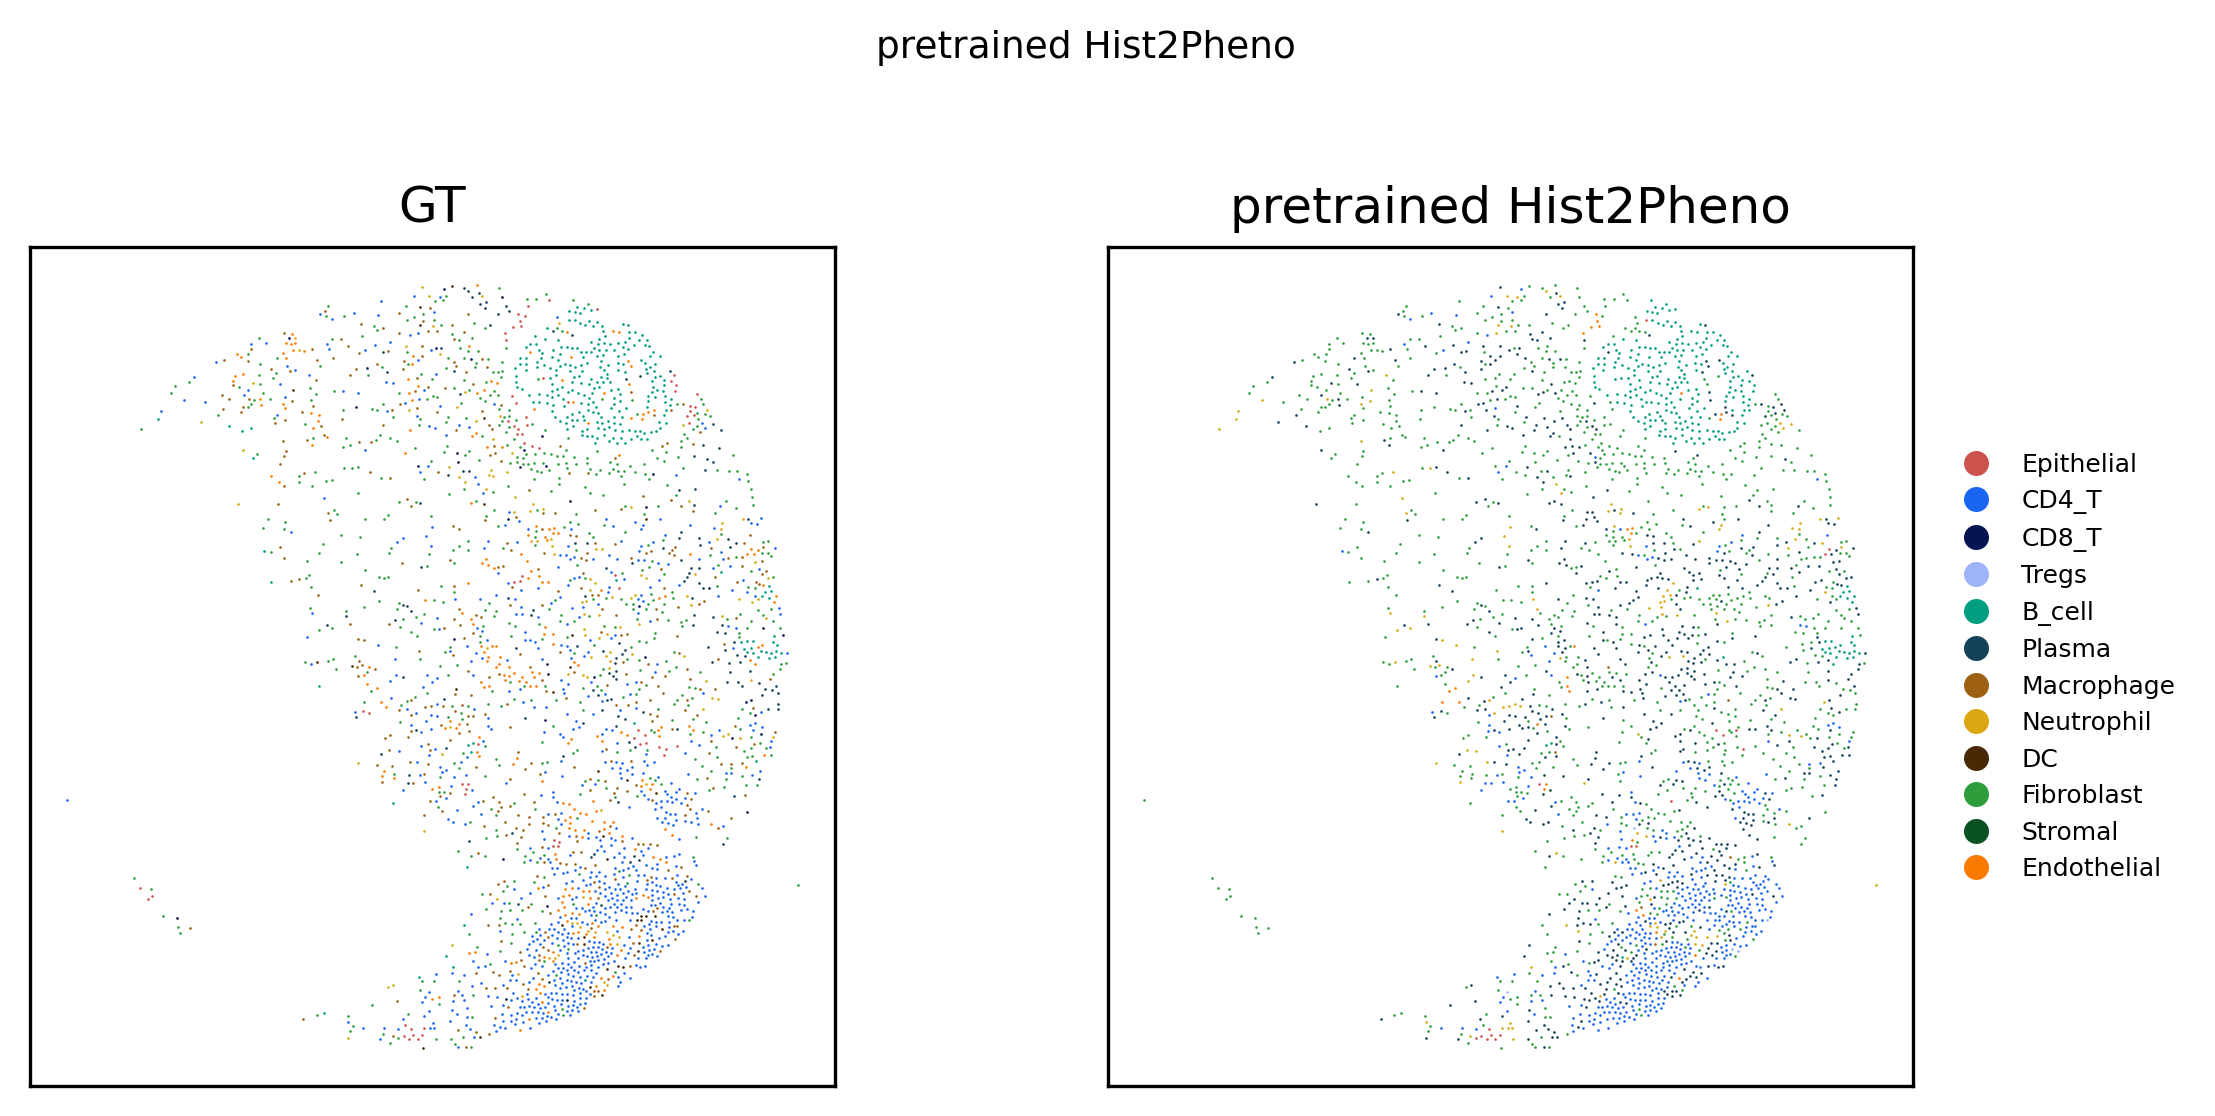

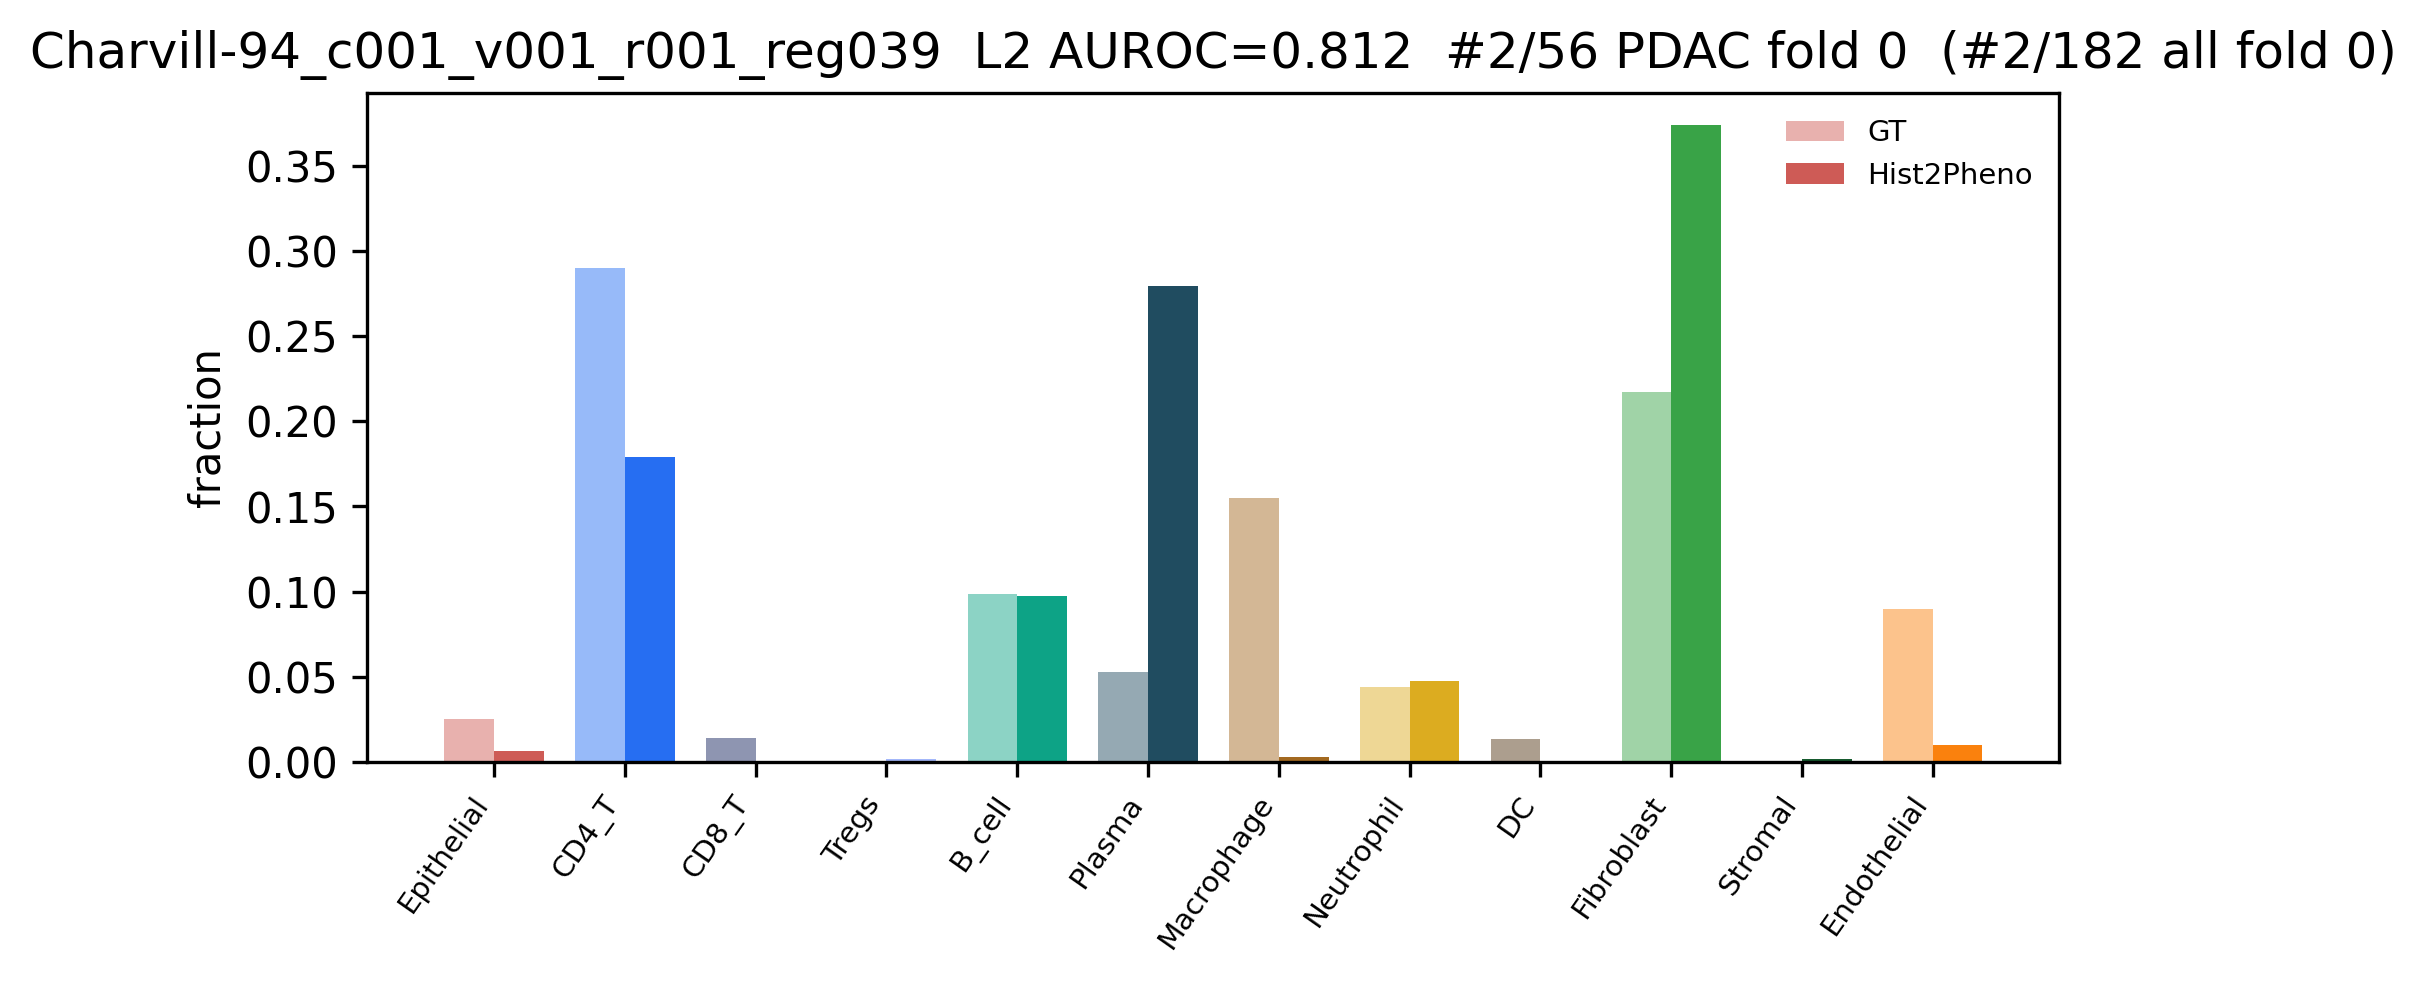

### Charvill-94_c001_v001_r001_reg059  L2 AUROC=0.801  #3/56 PDAC fold 0  (#3/182 all fold 0)

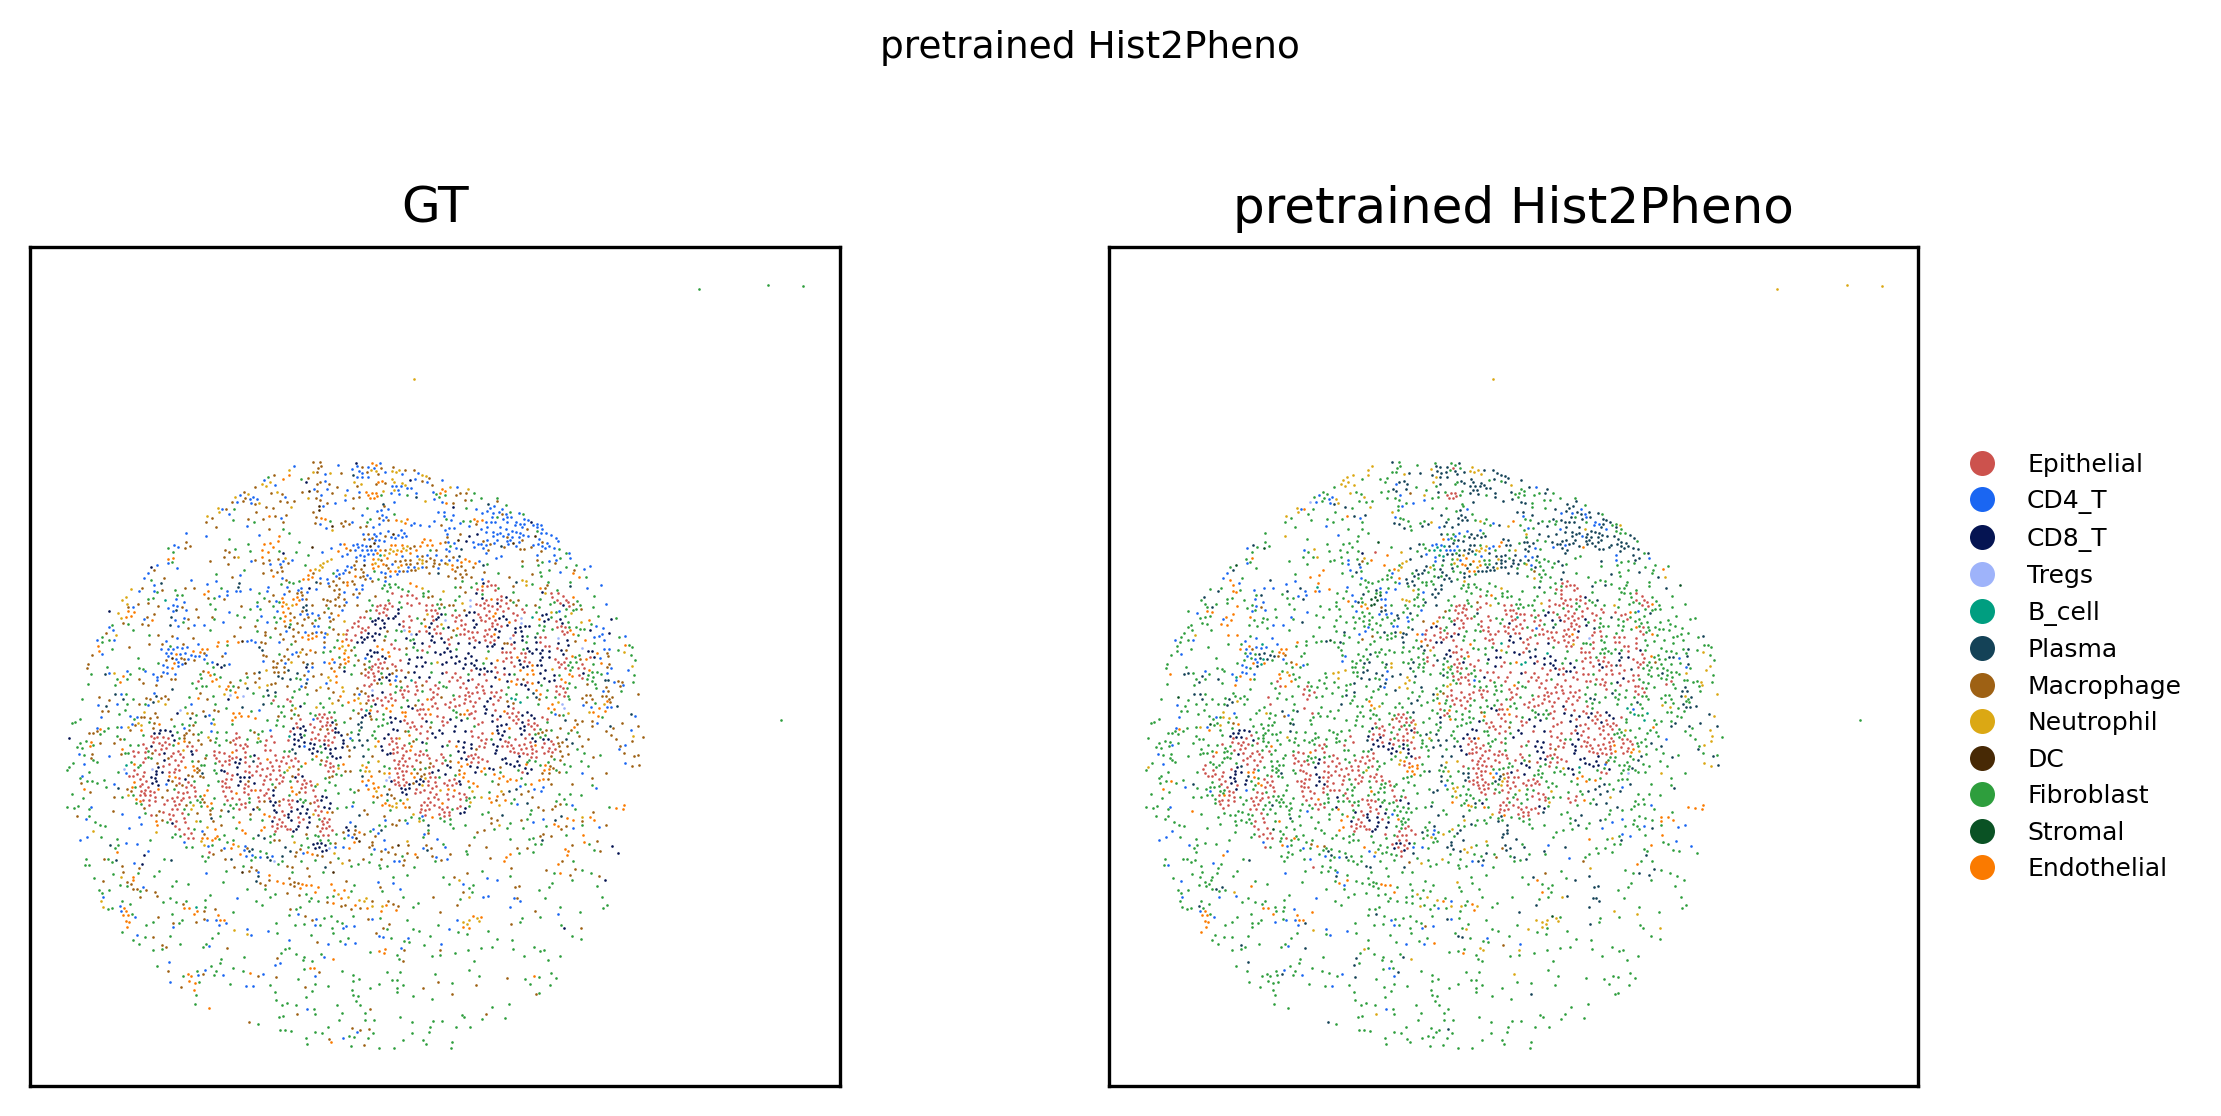

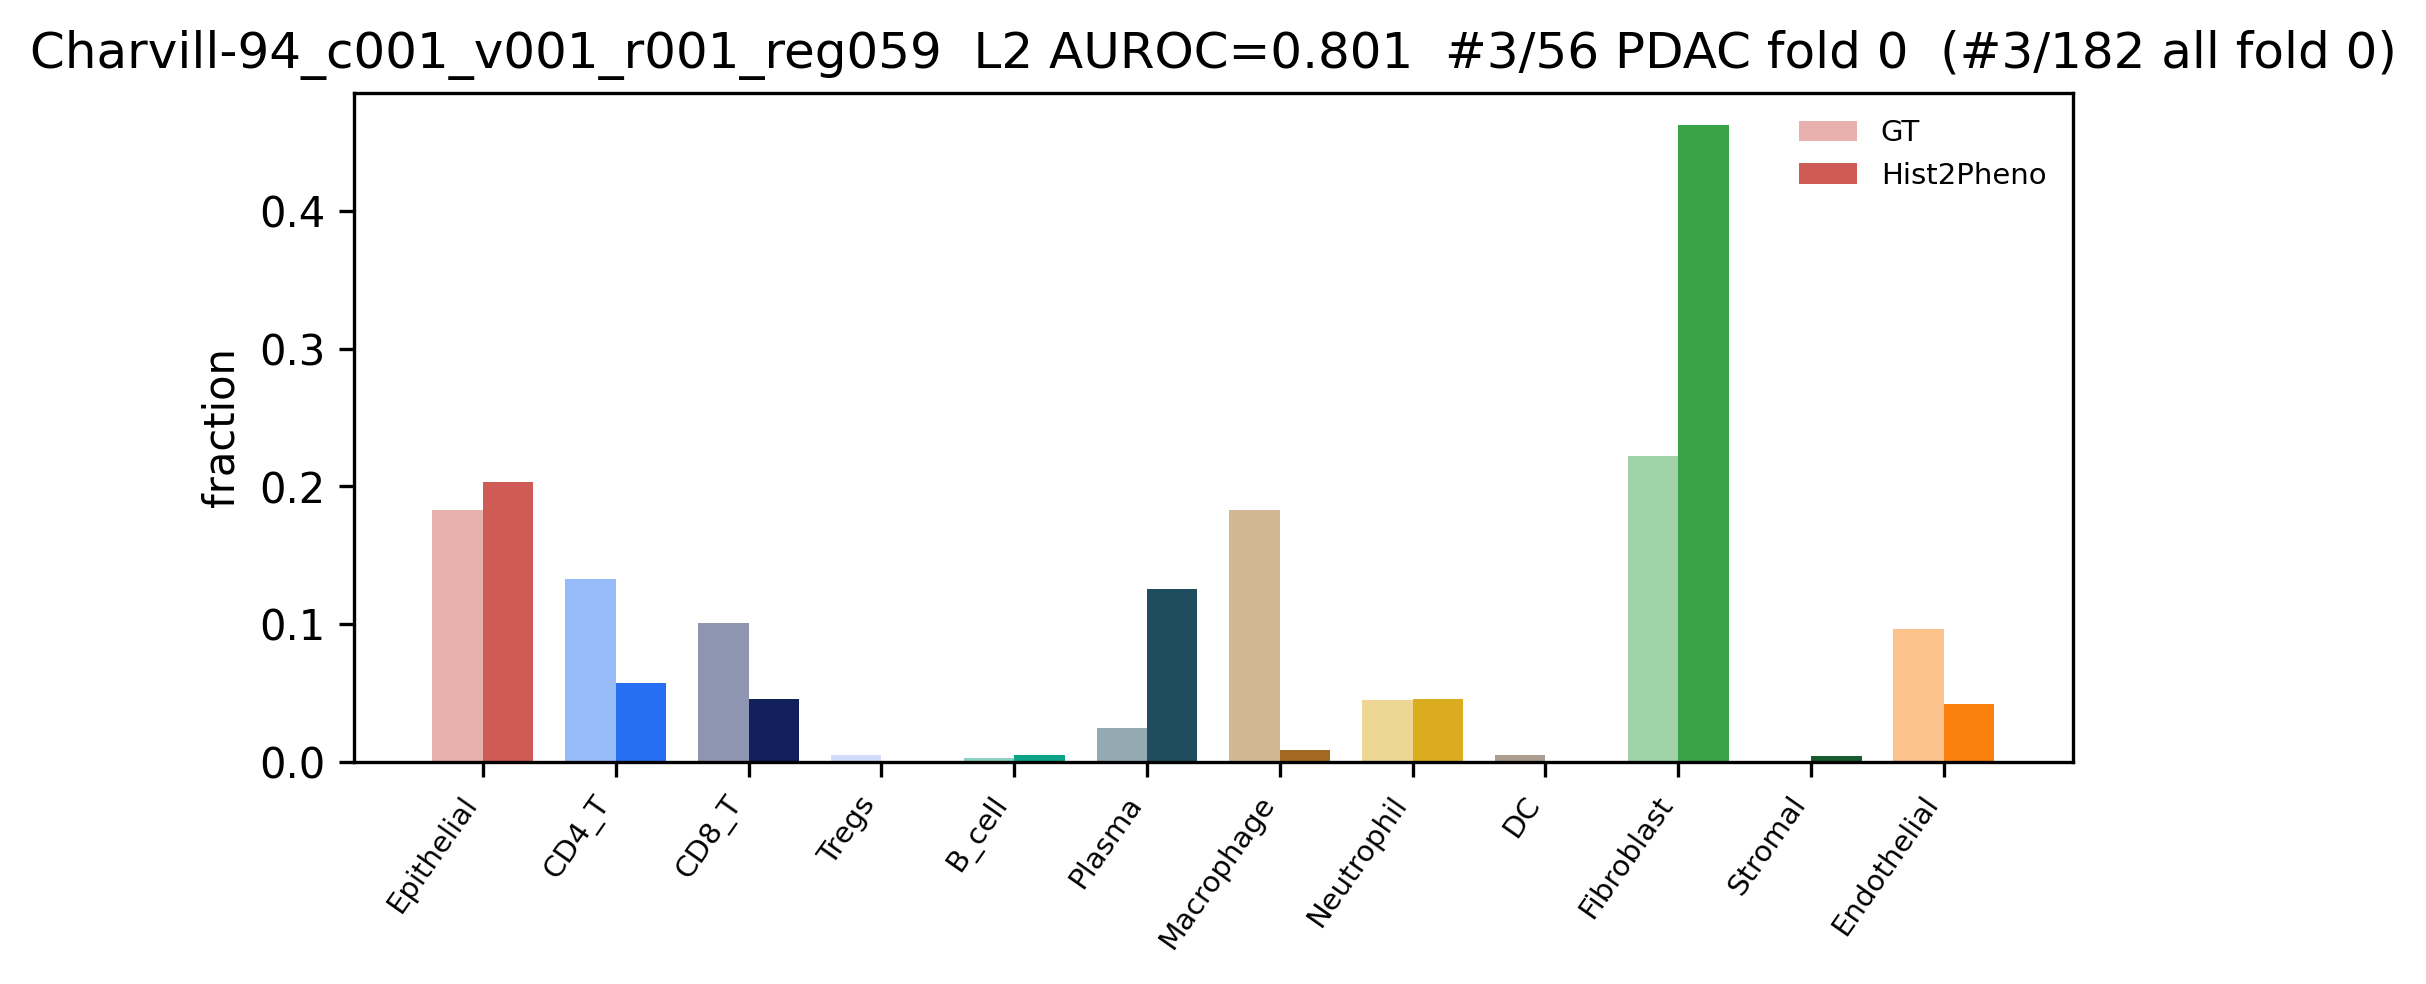

### Charvill-94_c001_v001_r001_reg087  L2 AUROC=0.801  #4/56 PDAC fold 0  (#4/182 all fold 0)

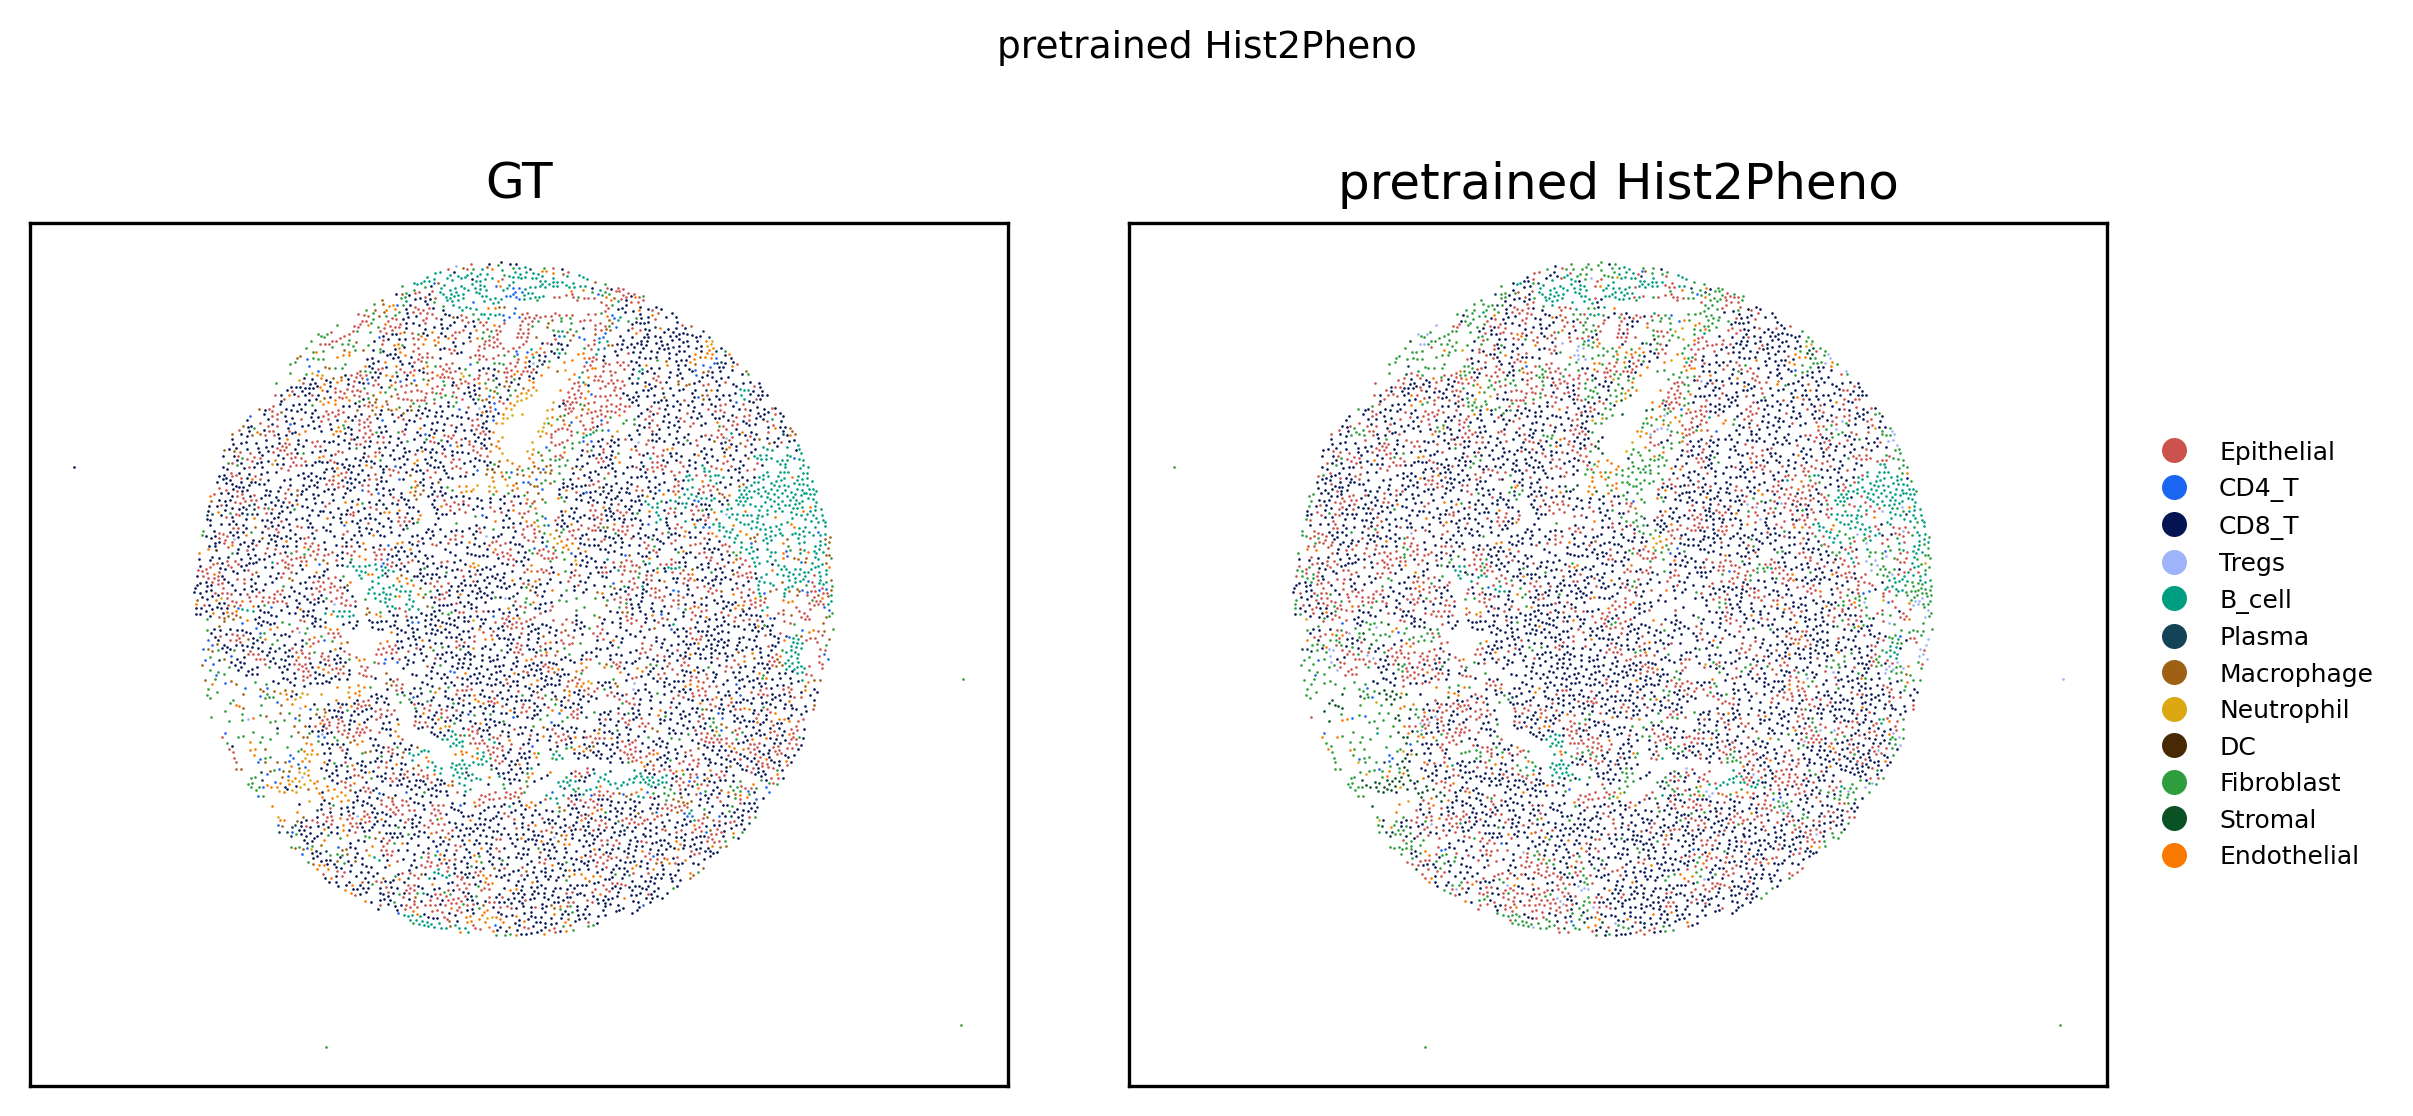

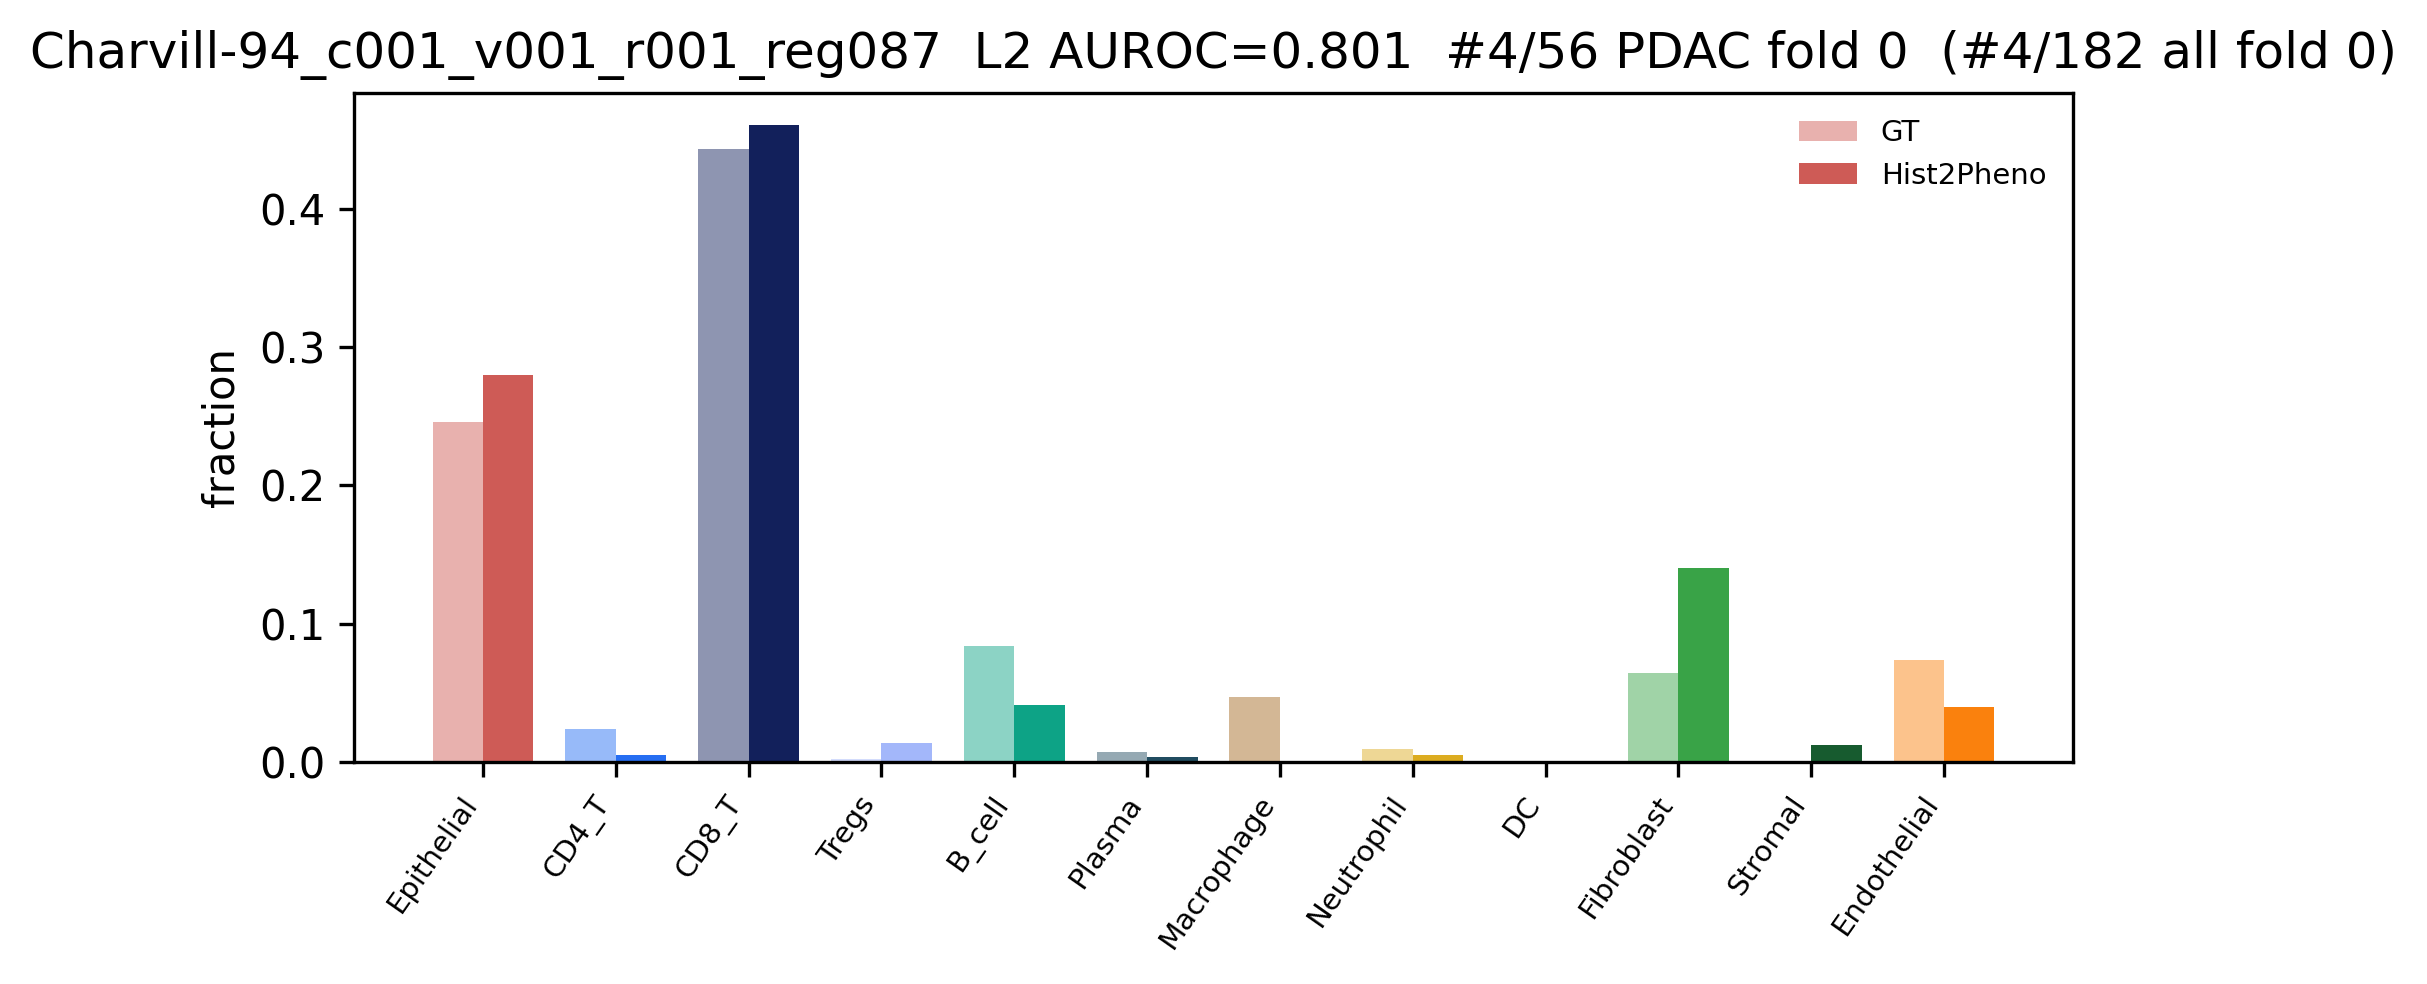

### Charvill-94_c003_v001_r001_reg111  L2 AUROC=0.799  #5/56 PDAC fold 0  (#5/182 all fold 0)

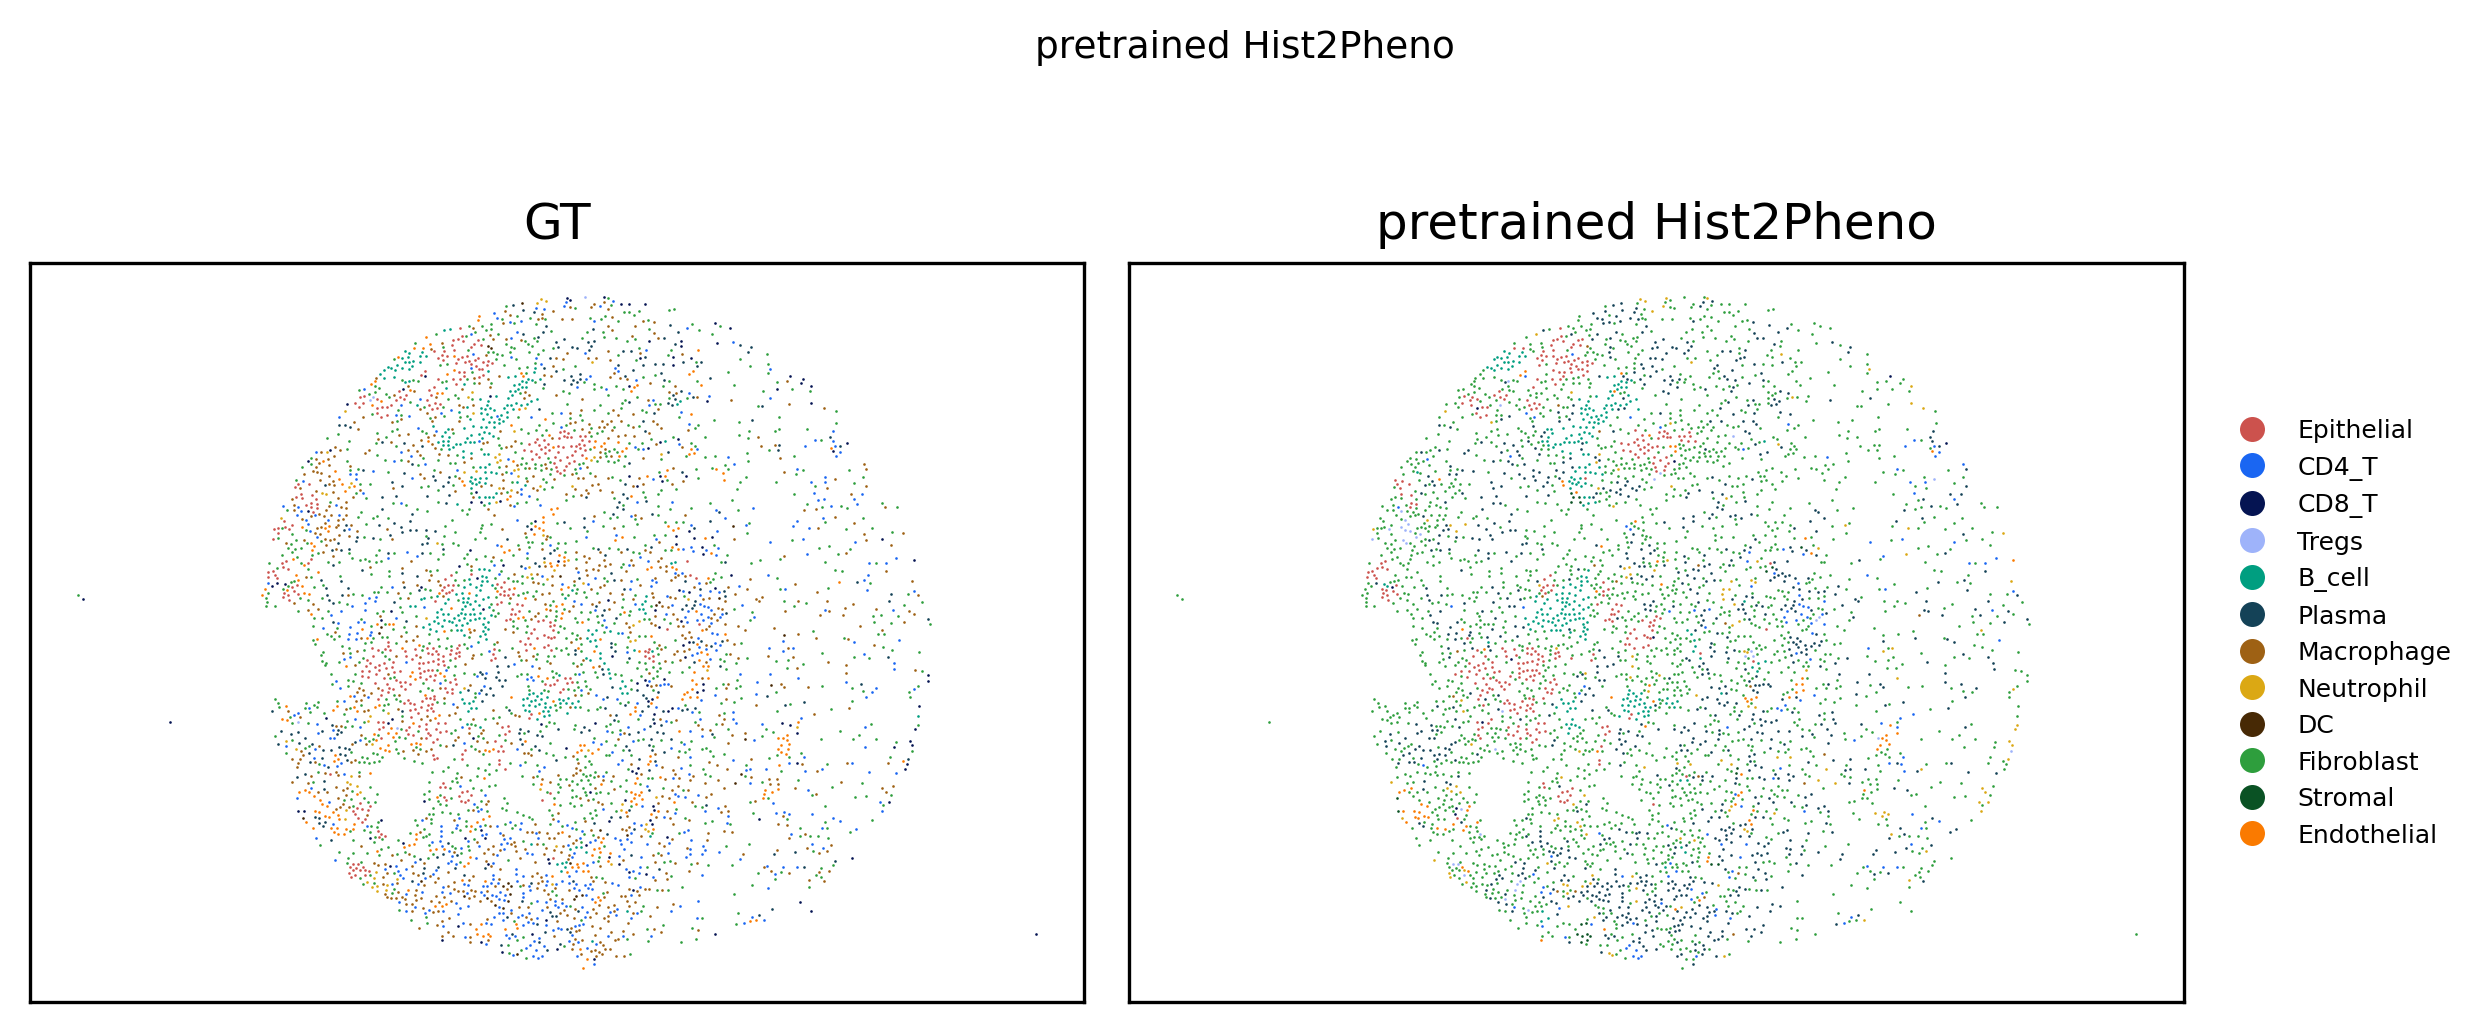

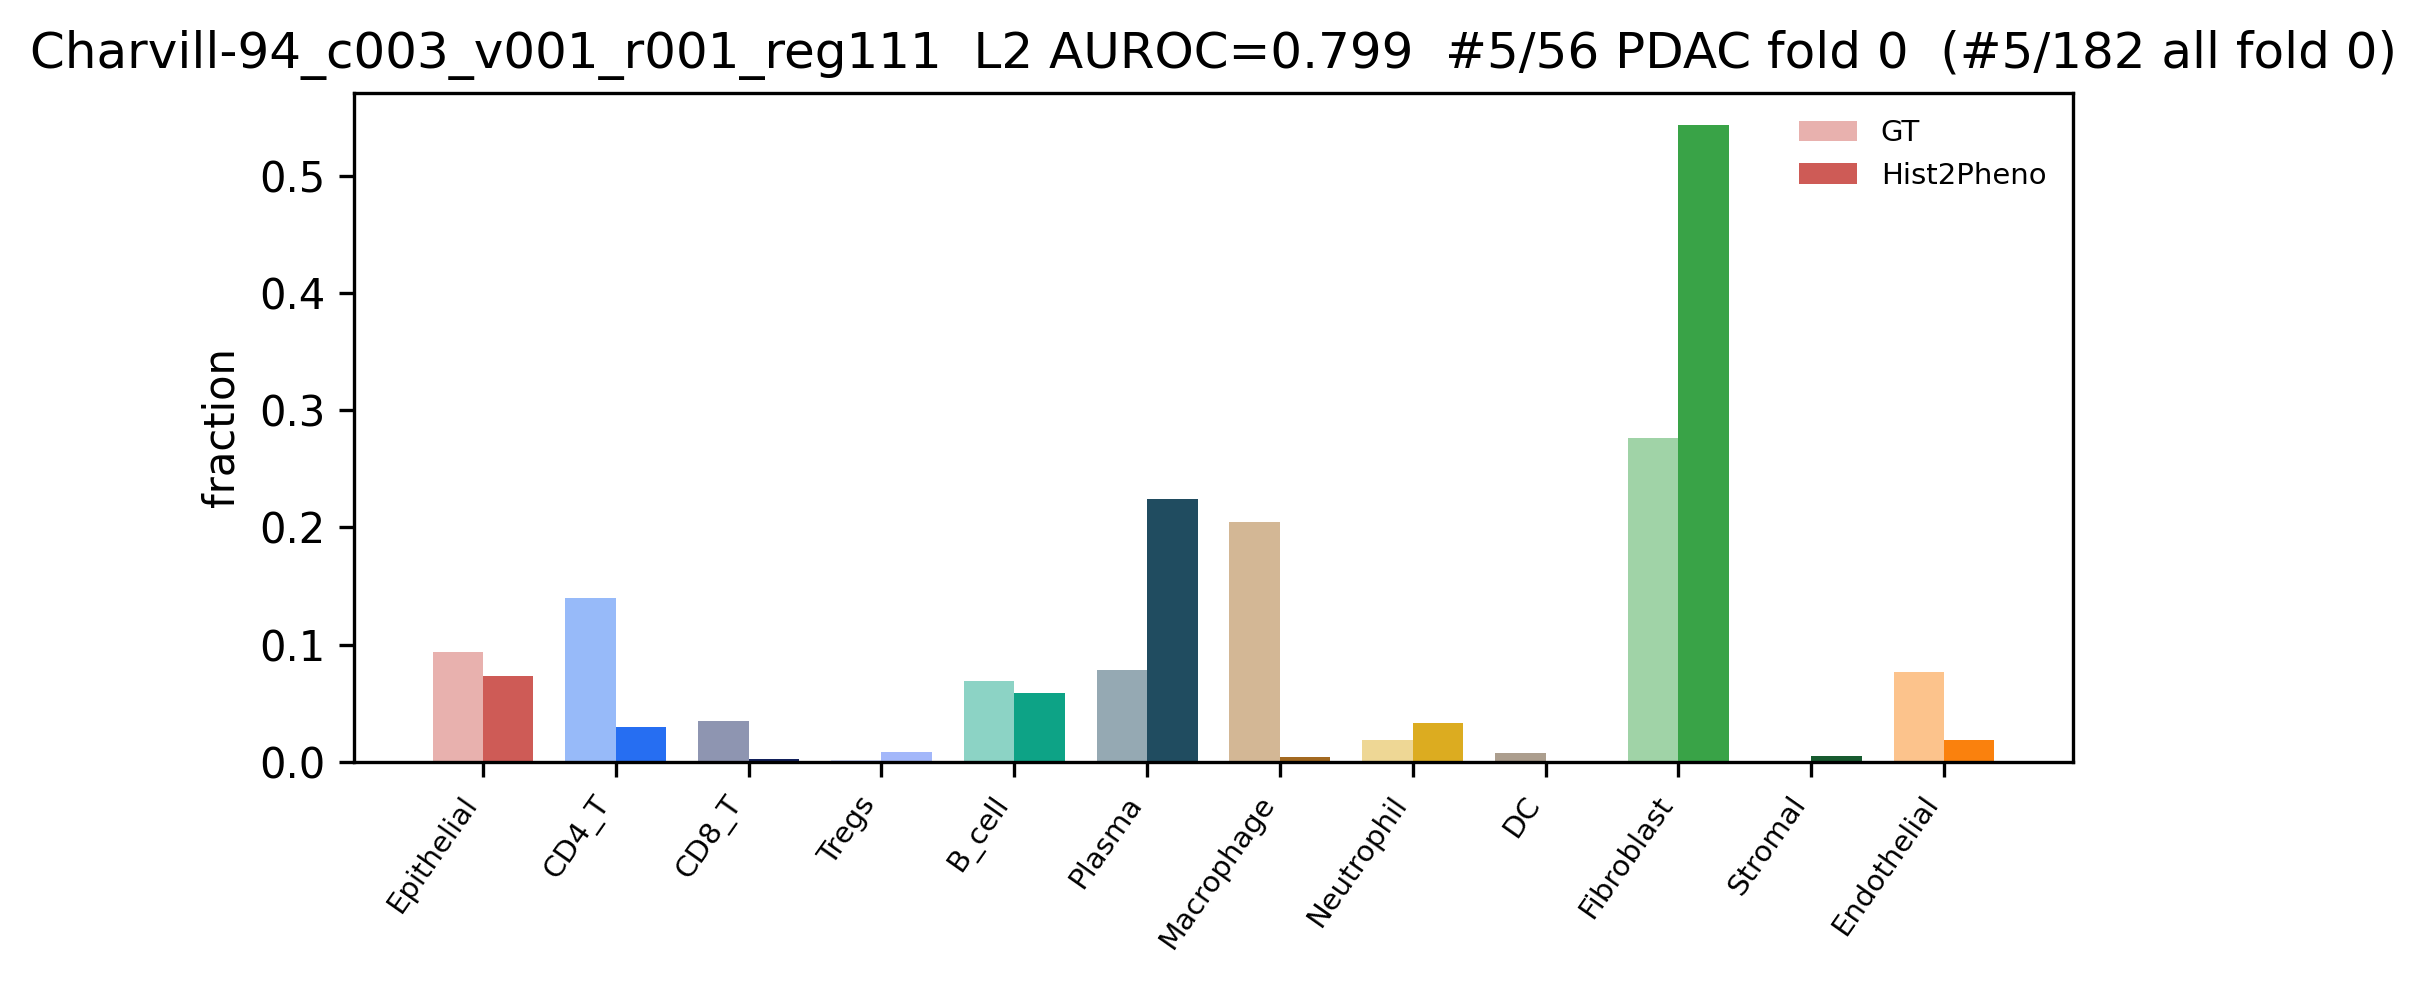

Saved paper figures → `/nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_all_spatial/internal_val_figures/PDAC_fold0_top5`

In [3]:
display(Markdown("## Top 5 — GT vs pretrained L2 (matched nuclei)"))
for sample in viz:
    pred = iv.pred_paths(DATASET, sample)["pred"]
    if not pred.is_file():
        print("skip", sample, "(no matched_pred.h5ad)")
        continue
    display(Markdown(f"### {iv.rank_label(DATASET, sample)}"))
    fig = iv.plot_spatial_gt_pred(DATASET, sample, "L2", save=SAVE_FIGURES)
    display(fig)
    plt.close(fig)
    fig = iv.plot_composition(DATASET, sample, "L2", save=SAVE_FIGURES)
    display(fig)
    plt.close(fig)

if SAVE_PAPER:
    out = iv.export_paper_sections(DATASET, viz)
    display(Markdown(f"Saved paper figures → `{out}`"))
